# Sesión 2/6 · Tipos de aprendizaje y preparación de datos de seguridad
**IA aplicada a la ciberseguridad · Máster en Ciberseguridad**  
**Cuaderno didáctico · Desde cero, con ejercicios resueltos y código comentado**

En la sesión 1 aprendimos a interpretar conexiones, entrenar un clasificador y distinguir entrenamiento de evaluación. En esta segunda sesión veremos **cómo preparar los datos sin engañarnos con resultados artificialmente buenos**. No necesitas recordar el código del primer notebook: aquí se recuerda lo imprescindible antes de utilizarlo.

Trabajaremos con **dos fuentes diferentes que no se mezclan**:

- **NSL-KDD**: tablas de conexiones de red etiquetadas como normales o ataques. Nos servirán para codificación, escalado, entrenamiento y evaluación.
- **`auth.log` sintético**: eventos de inicio de sesión SSH inventados para el laboratorio. Aprenderemos a convertir cientos de líneas de texto en un registro por dirección IP y ventana temporal.

| Parte | Problema que resolvemos | Qué aprendes a comprobar |
|:--|:--|:--|
| **A** | Examinar NSL-KDD antes de usarlo | Valores ausentes, duplicados, variables constantes y solapamiento |
| **B** | Agrupar etiquetas de ataques | Etiquetas originales frente a familias DoS, Probe, R2L y U2R |
| **C** | Convertir palabras en entradas numéricas | One-hot, frecuencia y fuga de información con *target encoding* |
| **D** | Poner números en escalas comparables | Media, desviación, z-score y transformación logarítmica |
| **E** | Transformar `auth.log` en una tabla | Expresiones regulares, agrupaciones temporales y ráfagas |
| **F** | Separar correctamente y entrenar | Divisiones aleatoria, temporal y por IP; `Pipeline` sin fuga |
| **G** | Afrontar una clase de ataque muy rara | `class_weight`, SMOTE, precisión y *recall* |

**Idea transversal:** antes de elegir un algoritmo, hay que preguntarse qué información habría disponible **de verdad** cuando el sistema reciba un caso nuevo.

## Antes de empezar · Vocabulario que utilizaremos

**Una fila u observación** representa una conexión de red en NSL-KDD, o una combinación de IP + intervalo de diez minutos en los registros SSH. **Una columna o característica** describe esa observación; por ejemplo, los bytes enviados (`src_bytes`) o la cantidad de intentos fallidos (`n_fail`).

**Una etiqueta o variable objetivo** es la respuesta que queremos predecir. En NSL-KDD, `is_attack=0` significa normal y `is_attack=1` significa ataque. En los logs sintéticos, `label=1` marcará ventanas creadas para simular fuerza bruta. **No confundas esa respuesta real con la predicción del modelo**: la primera sirve para aprender o evaluar; la segunda es lo que propone el algoritmo.

**Aprendizaje supervisado**: se conocen las respuestas de ejemplos anteriores y un modelo aprende patrones para responder sobre ejemplos nuevos. **Aprendizaje no supervisado**: no tenemos esas respuestas y buscamos estructuras o anomalías en los datos. Este laboratorio entrena clasificadores supervisados, aunque explorar y agrupar datos también es útil sin entrenarlos.

**`train` / entrenamiento** contiene ejemplos cuyas etiquetas se pueden usar para ajustar modelos y transformaciones. **`test` / prueba** contiene ejemplos reservados para medir el comportamiento con datos que no participaron en esos ajustes. Una **fuga de información** (*data leakage*) sucede cuando un procedimiento utiliza, directa o indirectamente, información de prueba que no debería conocer: entonces su resultado puede ser demasiado optimista.

**Sobre Python y las bibliotecas:** `pandas` representa tablas (`DataFrame`) y permite seleccionar o agrupar filas; `numpy` hace operaciones numéricas; `scikit-learn` proporciona transformadores y modelos. `fit(...)` significa «aprender parámetros a partir de estos datos»; `transform(...)` significa «aplicar una transformación ya aprendida»; `predict(...)` significa «obtener predicciones con un modelo ya entrenado».

> **Cómo ejecutarlo:** abre el `.ipynb` en Colab, Jupyter o VS Code. Ejecuta las celdas de arriba abajo con `Mayús + Intro`. En un entorno limpio, la primera ejecución necesita Internet para instalar dependencias ausentes y obtener NSL-KDD. Si se reinicia Colab, hay que repetir la preparación. Las rutas `data/`, `utils.py`, `auth.log` y `pipe_ia2.joblib` son relativas al directorio de ejecución. Al terminar, prueba **Reiniciar kernel → Ejecutar todo**.

## Preparación · Entorno, archivos y función de carga

**Objetivo:** poder ejecutar el laboratorio en una máquina nueva sin copiar archivos manualmente de la sesión 1. La celda siguiente comprueba las bibliotecas necesarias, descarga los dos conjuntos de NSL-KDD solo si faltan y crea `utils.py` si no existe.

**Qué hay en los ficheros:** `KDDTrain+.txt` y `KDDTest+.txt` contienen filas de **43 columnas sin encabezados**: 41 características de conexión, el nombre del tipo de tráfico (`label`) y un campo de dificultad (`difficulty`). La función `load_nsl_kdd` les asigna los nombres y añade `is_attack`, que vale **0** para `normal` y **1** para cualquier otro nombre de ataque: el `DataFrame` resultante tiene **44 columnas**.

`utils.py` no es una herramienta externa: es un **archivo `.py` con funciones reutilizables**. Para que este cuaderno también pueda ejecutarse después de la sesión anterior, **no sobrescribimos** un `utils.py` existente durante la preparación. Más adelante añadiremos de forma controlada una función nueva. No es necesario recordar todos los nombres de las 41 características; examinaremos las relevantes cuando aparezcan.

**Limitación del dato:** NSL-KDD es un conjunto histórico preparado para investigación; no representa tráfico moderno ni tasas de ataque de una red en producción.

In [6]:
# 0) Preparar el entorno. Esta celda se ejecuta antes de cargar los datos.
import importlib.util
import os
import subprocess
import sys
import urllib.request
from pathlib import Path

from IPython.display import display

esta_en_colab = "google.colab" in sys.modules
print("=" * 72)
print("PREPARACIÓN · Entorno de ejecución")
print("=" * 72)
print(f"Plataforma: {'Google Colab' if esta_en_colab else 'Jupyter / VS Code / Codespaces'}")
print(f"Python: {sys.version.split()[0]}")

# El nombre que se importa en Python no siempre es el nombre usado por pip.
bibliotecas = {
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "imblearn": "imbalanced-learn",
    "joblib": "joblib",
}
pendientes = [
    paquete_pip
    for modulo, paquete_pip in bibliotecas.items()
    if importlib.util.find_spec(modulo) is None
]

if pendientes:
    print(f"\nInstalando bibliotecas que faltan: {', '.join(pendientes)}")
    # sys.executable usa el Python del propio notebook, no otro del sistema.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pendientes])
else:
    print("\nBibliotecas necesarias: ya instaladas.")

# Descarga reproducible: se conserva cualquier archivo que ya exista.
url_base = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
carpeta_datos = Path("data")
carpeta_datos.mkdir(exist_ok=True)
print("\n" + "-" * 72)
print("Archivos de NSL-KDD (el primero es entrenamiento; el segundo, prueba)")
for nombre_archivo in ["KDDTrain+.txt", "KDDTest+.txt"]:
    archivo = carpeta_datos / nombre_archivo
    if not archivo.exists():
        # El '+' es especial en algunas URLs y se codifica como %2B.
        urllib.request.urlretrieve(url_base + nombre_archivo.replace("+", "%2B"), archivo)
        procedencia = "descargado ahora"
    else:
        procedencia = "ya existía; se reutiliza"
    print(f"{nombre_archivo}: {archivo.stat().st_size / 1e6:.2f} MB ({procedencia})")

import numpy as np
import pandas as pd
import sklearn

print("\nVersiones:")
print(f"numpy {np.__version__} · pandas {pd.__version__} · scikit-learn {sklearn.__version__}")

# El módulo se crea solo si falta, para respetar el archivo de la sesión 1.
contenido_utils = """# Funciones compartidas de carga y preparación del dataset NSL-KDD.
import os
import urllib.request
import pandas as pd

NSL_URL = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
NSL_COLS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land",
    "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in", "num_compromised",
    "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
    "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "label", "difficulty",
]

def load_nsl_kdd(split="train", base="data"):
    # Lee train o test; crea la etiqueta binaria 0 normal / 1 ataque.
    nombre = "KDDTrain+.txt" if split == "train" else "KDDTest+.txt"
    ruta = os.path.join(base, nombre)
    if not os.path.exists(ruta):
        os.makedirs(base, exist_ok=True)
        urllib.request.urlretrieve(NSL_URL + nombre.replace("+", "%2B"), ruta)
    datos = pd.read_csv(ruta, header=None, names=NSL_COLS)
    datos["is_attack"] = (datos["label"] != "normal").astype(int)
    return datos
"""

if not Path("utils.py").exists():
    Path("utils.py").write_text(contenido_utils, encoding="utf-8")
    print("\nutils.py: creado (incluye load_nsl_kdd).")
else:
    print("\nutils.py: existente; conservamos su contenido.")

PREPARACIÓN · Entorno de ejecución
Plataforma: Jupyter / VS Code / Codespaces
Python: 3.12.3

Bibliotecas necesarias: ya instaladas.

------------------------------------------------------------------------
Archivos de NSL-KDD (el primero es entrenamiento; el segundo, prueba)
KDDTrain+.txt: 19.11 MB (ya existía; se reutiliza)
KDDTest+.txt: 3.44 MB (ya existía; se reutiliza)

Versiones:
numpy 2.5.5 · pandas 3.1.1 · scikit-learn 1.9.1

utils.py: existente; conservamos su contenido.


**Qué deberías observar:** dos tamaños de archivo en MB, las versiones instaladas y el mensaje sobre `utils.py`. El tamaño no es una métrica del modelo: solo verifica que los archivos existen. Si la descarga falla, comprueba la conexión a Internet o coloca manualmente `KDDTrain+.txt` y `KDDTest+.txt` en `data/`. Si la ejecución se detiene por una biblioteca incompatible, revisa las versiones de Python y de los paquetes antes de continuar.

## Parte A · Perfilar y limpiar NSL-KDD

**Objetivo:** comprobar si los datos contienen errores evidentes o elementos que pueden distorsionar una evaluación **antes** de entrenar. «Perfilar» significa explorar su estructura y calidad; «limpiar» significa decidir y aplicar cambios justificados, no borrar filas sin pensar.

- **Valor nulo:** falta un dato (`NaN`). No equivale al número cero: cero puede significar que se enviaron cero bytes; un nulo significa que no conocemos la cantidad.
- **Duplicado exacto:** dos filas coinciden en *todas* sus columnas; podría ser un error o una observación repetida legítimamente. Aquí contamos duplicados exactos dentro de cada archivo.
- **Variable categórica:** contiene categorías como `tcp`, `udp` o `icmp` en lugar de una cantidad medible. `nunique()` cuenta sus valores distintos.
- **Solapamiento entre entrenamiento y prueba:** dos archivos contienen registros con las mismas **características de entrada**; aunque la etiqueta o el campo `difficulty` difieran, la conexión observable podría ser idéntica. Eso compromete la independencia de la evaluación.

**Diferencia importante:** que un registro aparezca duplicado dentro de entrenamiento no demuestra automáticamente que haya un solapamiento con prueba. Son comprobaciones distintas.

In [7]:
import numpy as np
import pandas as pd
from utils import load_nsl_kdd

# Cada llamada devuelve un DataFrame: filas = conexiones, columnas = atributos.
datos_train = load_nsl_kdd("train")
datos_test = load_nsl_kdd("test")

print("=" * 72)
print("PARTE A · 1. Tamaño y tipos de datos")
print("=" * 72)
print(f"Entrenamiento: {len(datos_train):,} conexiones; {datos_train.shape[1]} columnas")
print(f"Prueba:        {len(datos_test):,} conexiones; {datos_test.shape[1]} columnas")
print("\nTipos de dato de pandas en entrenamiento (número de columnas):")
display(datos_train.dtypes.astype(str).value_counts().rename_axis("Tipo").to_frame("Columnas"))

# isna() indica celdas ausentes; sum() suma primero por columna y después el total.
nulos_train = int(datos_train.isna().sum().sum())
nulos_test = int(datos_test.isna().sum().sum())

# duplicated() marca como repetidas las apariciones posteriores a la primera.
duplicados_train = int(datos_train.duplicated().sum())
duplicados_test = int(datos_test.duplicated().sum())
print("\n" + "-" * 72)
print("2. Calidad: ausencias y duplicados exactos")
display(pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Celdas nulas": [nulos_train, nulos_test],
    "Filas duplicadas exactas": [duplicados_train, duplicados_test],
}))

print("\n" + "-" * 72)
print("3. Número de categorías distintas en tres características")
display(datos_train[["protocol_type", "service", "flag"]].nunique()
        .rename_axis("Característica").to_frame("Valores diferentes (train)"))

# Comparamos características observables, no la respuesta ni el metadato difficulty.
columnas_entrada = [
    columna
    for columna in datos_train.columns
    if columna not in ("label", "difficulty", "is_attack")
]
filas_comunes = pd.merge(
    datos_train[columnas_entrada].drop_duplicates(),
    datos_test[columnas_entrada].drop_duplicates(),
    how="inner",
)
print("\n" + "-" * 72)
print("4. Coincidencias entre train y test (por sus 41 características)")
print(f"Patrones de entrada idénticos en ambos archivos: {len(filas_comunes):,}")
print("Se cuentan patrones distintos, no todas las apariciones duplicadas.")

PARTE A · 1. Tamaño y tipos de datos
Entrenamiento: 125,973 conexiones; 44 columnas
Prueba:        22,544 conexiones; 44 columnas

Tipos de dato de pandas en entrenamiento (número de columnas):


,Columnas
Tipo,
int64,25
float64,15
str,4



------------------------------------------------------------------------
2. Calidad: ausencias y duplicados exactos


,Conjunto,Celdas nulas,Filas duplicadas exactas
0,Entrenamiento,0,0
1,Prueba,0,0



------------------------------------------------------------------------
3. Número de categorías distintas en tres características


,Valores diferentes (train)
Característica,
protocol_type,3
service,70
flag,11



------------------------------------------------------------------------
4. Coincidencias entre train y test (por sus 41 características)
Patrones de entrada idénticos en ambos archivos: 654
Se cuentan patrones distintos, no todas las apariciones duplicadas.


### A.1 · Interpretar el diagnóstico y resolver la limpieza

**Pregunta 1. ¿Cuántos duplicados hay? ¿Los eliminarías?** Las cantidades correctas son las que muestra la tabla anterior para los dos archivos: `duplicados_train` y `duplicados_test` cuentan **filas completas repetidas**, no «mismo `service`» o «misma IP». **No los eliminaría automáticamente**: si hay conexiones repetidas legítimas, borrarlas cambia la distribución del problema. En una evaluación de detección sí investigaría si corresponden a copias accidentales y documentaría su eliminación cuando proceda. Por eso **contamos, pero no borramos filas** en este laboratorio; no cambiamos el conjunto que después se utiliza para entrenar y comparar.

**Pregunta 2. ¿Qué es una columna constante y por qué se elimina?** Si una característica vale siempre lo mismo en el entrenamiento, no ayuda al modelo a distinguir unos ejemplos de otros. Por ejemplo, si `num_outbound_cmds` siempre vale 0, no permite identificar qué conexiones son ataques. La siguiente celda **detecta las columnas con un único valor en train** y las elimina de **train y test** para que ambas tablas mantengan la misma estructura. Se excluyen las etiquetas y metadatos de la selección: no son características candidatas.

**Pregunta 3. ¿Qué riesgo hay con filas idénticas entre train y test?** El clasificador podría reconocer un patrón ya visto en lugar de generalizar ante situaciones nuevas, y la métrica de prueba parecer mejor de lo que sería en producción. Comparar solo características observables es deliberado: si dos filas tienen las mismas entradas pero etiquetas distintas, también es una señal que merece investigarse. **Un solapamiento exacto no demuestra por sí solo que todo modelo memorice**; sí demuestra que las muestras no son totalmente independientes.

In [8]:
# Una columna constante tiene exactamente 1 valor distinto en el entrenamiento.
# No consideramos 'label', 'difficulty' ni 'is_attack': son etiquetas/metadatos.
columnas_excluidas = {"label", "difficulty", "is_attack"}
columnas_constantes = [
    columna
    for columna in datos_train.columns
    if columna not in columnas_excluidas and datos_train[columna].nunique() == 1
]

print("=" * 72)
print("PARTE A · 5. Eliminar características constantes")
print("=" * 72)
if columnas_constantes:
    display(pd.DataFrame({
        "Columna constante": columnas_constantes,
        "Único valor en train": [datos_train[col].iloc[0] for col in columnas_constantes],
    }))
else:
    print("No se encontraron características constantes en entrenamiento.")

# Quitamos las mismas columnas de ambos conjuntos; no tocamos las filas.
# errors='ignore' hace segura una segunda ejecución de esta celda.
datos_train = datos_train.drop(columns=columnas_constantes, errors="ignore")
datos_test = datos_test.drop(columns=columnas_constantes, errors="ignore")

print(f"Columnas retiradas de ambas tablas: {len(columnas_constantes)}")
print(f"Columnas que quedan · train: {datos_train.shape[1]} | test: {datos_test.shape[1]}")
print("Filas conservadas: entrenamiento y prueba no se deduplican automáticamente.")

PARTE A · 5. Eliminar características constantes


,Columna constante,Único valor en train
0,num_outbound_cmds,0


Columnas retiradas de ambas tablas: 1
Columnas que quedan · train: 43 | test: 43
Filas conservadas: entrenamiento y prueba no se deduplican automáticamente.


**Cómo leer el resultado:** «columnas retiradas» se refiere solo a **características sin variación en entrenamiento**. La cantidad de conexiones sigue igual: `.drop(columns=...)` borra columnas, no filas. Si una variable es constante en entrenamiento pero varía en test, sigue siendo razonable retirarla para este experimento: el modelo no puede aprender con train cómo aprovechar esos cambios. Tampoco significa que «todas las variables con muchos ceros» sean constantes.

> **Precaución metodológica:** en un proyecto real, cualquier selección de columnas que dependa de estadísticas de datos se aprende **solo en train**. Aquí hacemos precisamente eso, y después aplicamos la misma selección a test.

## Parte B · De nombres de ataque a cinco clases: normal + cuatro familias

**Objetivo:** convertir la columna original `label`, que contiene nombres concretos de ataques, en una columna `category` más sencilla para investigar **familias de comportamiento**. Por ejemplo, `neptune` y `smurf` no son el mismo ataque, pero ambos pertenecen aquí a la familia **DoS**.

| Categoría nueva | Significado | Ejemplo en NSL-KDD |
|:--|:--|:--|
| `normal` | Conexión etiquetada como no maliciosa | `normal` |
| `dos` | Denial of Service: degradar o impedir un servicio | `neptune` |
| `probe` | Reconocimiento o sondeo de objetivos | `nmap` |
| `r2l` | Remote-to-Local: intentar conseguir acceso local desde una conexión remota | `guess_passwd` |
| `u2r` | User-to-Root: obtener privilegios superiores desde un usuario existente | `buffer_overflow` |

**Son cuatro familias de ataque, pero cinco categorías contando `normal`.** El título original «de 23 tipos a 4 categorías» se refiere a los tipos de tráfico del conjunto de entrenamiento histórico; **no significa que el test contenga exactamente los mismos nombres**. Por eso el diccionario del ejercicio recoge también ataques que pueden aparecer solo en prueba.

Un **diccionario** de Python asocia claves a valores: `{"neptune": "dos"}` significa «cuando veas `neptune`, escribe `dos`». `Series.map(diccionario)` aplica esa traducción a todas las filas. Si una etiqueta no figura como clave, aparece `NaN`: eso se comprueba antes de continuar, en vez de inventar una familia para ella.

In [9]:
# Diccionario de nombres específicos -> familias, con el mapa del ejercicio.
# Las comprensiones de diccionario generan una pareja 'ataque: familia'
# por cada nombre de la lista; ** combina los diccionarios resultantes.
mapa_ataques = {
    "normal": "normal",
    **{ataque: "dos" for ataque in [
        "back", "land", "neptune", "pod", "smurf", "teardrop",
        "apache2", "udpstorm", "processtable", "mailbomb",
    ]},
    **{ataque: "probe" for ataque in [
        "satan", "ipsweep", "nmap", "portsweep", "mscan", "saint",
    ]},
    **{ataque: "r2l" for ataque in [
        "guess_passwd", "ftp_write", "imap", "phf", "multihop",
        "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
        "snmpguess", "snmpgetattack", "httptunnel", "sendmail",
    ]},
    **{ataque: "u2r" for ataque in [
        "buffer_overflow", "loadmodule", "rootkit", "perl",
        "sqlattack", "xterm", "ps",
    ]},
}

# Se crea una columna nueva, sin modificar las etiquetas originales.
for tabla in (datos_train, datos_test):
    tabla["category"] = tabla["label"].map(mapa_ataques)

print("=" * 72)
print("PARTE B · Distribución por familia (normal + 4 familias de ataque)")
print("=" * 72)
frecuencias_por_categoria = pd.DataFrame({
    "Entrenamiento · conexiones": datos_train["category"].value_counts(dropna=False),
    "Prueba · conexiones": datos_test["category"].value_counts(dropna=False),
}).fillna(0).astype(int)
display(frecuencias_por_categoria.rename_axis("Familia de tráfico"))

print("\nEjemplos de traducción del nombre original a familia:")
display(datos_train[["label", "category"]].drop_duplicates().head(10)
        .rename(columns={"label": "Etiqueta específica", "category": "Familia"}))

PARTE B · Distribución por familia (normal + 4 familias de ataque)


,Entrenamiento · conexiones,Prueba · conexiones
Familia de tráfico,,
dos,45927,7458
normal,67343,9711
probe,11656,2421
r2l,995,2868
u2r,52,67
NaN,0,19



Ejemplos de traducción del nombre original a familia:


,Etiqueta específica,Familia
0,normal,normal
2,neptune,dos
13,warezclient,r2l
17,ipsweep,probe
33,portsweep,probe
46,teardrop,dos
56,nmap,probe
62,satan,probe
138,smurf,dos
211,pod,dos


### B.1 · Comprobar etiquetas que faltan y guardar la función

**Por qué mirar `NaN`:** una categoría ausente puede significar que el diccionario está incompleto. No equivale a `normal`: un ataque desconocido no se vuelve benigno por no figurar en la lista. La próxima celda enumera los nombres que no se han podido traducir **por separado en train y test**. El mapa suministrado cubre los nombres conocidos de los archivos NSL-KDD habituales; si utilizas una variante del dataset, revisa las etiquetas que aparezcan y asigna las familias justificadamente.

**Por qué guardar una función:** en lugar de copiar el mismo `.map(...)` en cada notebook, una función `add_category(df)` permitirá repetirlo en otras sesiones. Escribiremos esa función en `utils.py`. Para que **ejecutar varias veces el notebook no añada copias idénticas al archivo**, escribiremos una sección entre marcadores que se sustituye si ya existe, respetando las demás funciones de `utils.py`.

In [23]:
# Verificamos qué nombres originales no tienen correspondencia en el mapa.
etiquetas_sin_familia_train = sorted(
    datos_train.loc[datos_train["category"].isna(), "label"].unique().tolist()
)
etiquetas_sin_familia_test = sorted(
    datos_test.loc[datos_test["category"].isna(), "label"].unique().tolist()
)

print("=" * 72)
print("PARTE B · Comprobación de cobertura del diccionario")
print("=" * 72)
print(f"Etiquetas sin familia en entrenamiento ({len(etiquetas_sin_familia_train)}): {etiquetas_sin_familia_train}")
print(f"Etiquetas sin familia en prueba ({len(etiquetas_sin_familia_test)}): {etiquetas_sin_familia_test}")
print("Un listado vacío [] indica que todas las etiquetas de ese conjunto están cubiertas.")

# No ocultamos errores de clasificación asignando 'normal' a desconocidos.
if etiquetas_sin_familia_train or etiquetas_sin_familia_test:
    raise ValueError(
        "Hay etiquetas sin familia. Revisa sus nombres y amplía 'mapa_ataques' "
        "con una correspondencia justificada antes de continuar."
    )

PARTE B · Comprobación de cobertura del diccionario
Etiquetas sin familia en entrenamiento (0): []
Etiquetas sin familia en prueba (2): ['named', 'worm']
Un listado vacío [] indica que todas las etiquetas de ese conjunto están cubiertas.


ValueError: Hay etiquetas sin familia. Revisa sus nombres y amplía 'mapa_ataques' con una correspondencia justificada antes de continuar.

In [11]:
from pathlib import Path
from pprint import pformat
import importlib
import utils

print("=" * 72)
print("PARTE B · Guardar add_category(df) en utils.py de forma reproducible")
print("=" * 72)

# Generamos el diccionario en texto a partir del mapa verificado arriba.
# pformat crea una representación válida de Python, legible en el archivo.
inicio_bloque = "# >>> SESION_2: add_category (inicio)"
fin_bloque = "# <<< SESION_2: add_category (fin)"
bloque_categoria = (
    inicio_bloque + "\n"
    + "ATTACK_MAP = " + pformat(mapa_ataques, sort_dicts=True) + "\n\n"
    + "def add_category(df):\n"
    + '    """Añade category: normal, dos, probe, r2l o u2r."""\n'
    + '    df["category"] = df["label"].map(ATTACK_MAP)\n'
    + "    return df\n"
    + fin_bloque
)

ruta_utils = Path("utils.py")
texto_anterior = ruta_utils.read_text(encoding="utf-8")

# Si ya existe la sección de la sesión 2, sustituimos SOLO esa sección;
# así no crece utils.py cada vez que pulsas 'Run All'.
if inicio_bloque in texto_anterior and fin_bloque in texto_anterior:
    inicio = texto_anterior.index(inicio_bloque)
    fin = texto_anterior.index(fin_bloque) + len(fin_bloque)
    texto_nuevo = texto_anterior[:inicio] + bloque_categoria + texto_anterior[fin:]
    accion = "actualizada"
else:
    texto_nuevo = texto_anterior.rstrip() + "\n\n" + bloque_categoria + "\n"
    accion = "añadida"

ruta_utils.write_text(texto_nuevo, encoding="utf-8")

# Python puede mantener la versión anterior del módulo en memoria:
# reload obliga a releer el archivo que acabamos de actualizar.
importlib.invalidate_caches()
importlib.reload(utils)
from utils import add_category

datos_train = add_category(datos_train)
datos_test = add_category(datos_test)
print(f"Función add_category(df) {accion} en: {ruta_utils.resolve()}")
print("Recuento tras aplicar la función guardada (entrenamiento):")
display(datos_train["category"].value_counts()
        .rename_axis("Familia").to_frame("Conexiones"))

PARTE B · Guardar add_category(df) en utils.py de forma reproducible
Función add_category(df) actualizada en: /home/gh0st_byt3/Downloads/0.Firefix/ia-Laboratorios_1_6/ia-ciberseguridad/notebooks/utils.py
Recuento tras aplicar la función guardada (entrenamiento):


,Conexiones
Familia,
normal,67343
dos,45927
probe,11656
r2l,995
u2r,52


**Interpretación:** llamar a `add_category(datos_train)` reproduce exactamente la traducción ya realizada; no debe modificar el número de filas ni la etiqueta original `label`. Tener la función en un archivo permite importar su lógica desde cualquier notebook ubicado en el mismo proyecto. Si vuelves a ejecutar esta celda, `utils.py` se mantiene sin copias adicionales.

> **Importante:** crear `category` utilizando `label` está bien para **analizar** el dataset o construir una **etiqueta objetivo**. No debes entregar `category` como entrada a un detector binario que predice `is_attack`: sería proporcionar indirectamente la respuesta que intentas predecir.

## Parte C · Codificar variables categóricas sin inventar un orden

**Objetivo:** los clasificadores numéricos necesitan números, pero categorías como `tcp`, `udp` o `icmp` son **nombres**, no cantidades. Si asignamos simplemente `tcp=1`, `udp=2`, `icmp=3`, algunos algoritmos podrían creer que `icmp` es «mayor» que `tcp` o que la distancia entre `tcp` y `udp` tiene sentido matemático. No es así.

**One-hot encoding** crea **una columna 0/1 por categoría aprendida**. Con las categorías `tcp`, `udp`, `icmp`, una fila `udp` puede representarse como `[0, 1, 0]` (según el orden de columnas). Así no imponemos una jerarquía ficticia. A cambio, una variable con muchos servicios posibles puede originar muchas columnas.

Con `OneHotEncoder`:

- `fit(datos_train[cat_cols])` **aprende qué categorías existen en entrenamiento**; no entrena todavía un clasificador.
- `transform(...)` convierte filas de train o test en matrices numéricas con **las mismas columnas y en el mismo orden**.
- `handle_unknown="ignore"` significa que una categoría no vista en entrenamiento produce **ceros en todas las columnas de esa variable** en lugar de interrumpir el programa. Es una opción práctica, pero el valor nuevo no se representa de forma individual.
- `sparse_output=False` solicita una matriz convencional de NumPy, fácil de inspeccionar; en producción, una matriz **dispersa** (*sparse*) ahorra memoria cuando hay muchos ceros.

**Codificación por frecuencia:** otra alternativa es reemplazar cada servicio por la **proporción de filas de train** que usan ese servicio. Ejemplo: si `http` aparece 25 veces entre 100 conexiones, recibe `0,25`. No usa etiquetas de ataque: solo observa la frecuencia del nombre. Es más compacta, pero dos servicios distintos pueden tener la misma frecuencia y, por tanto, el mismo número.

In [12]:
from sklearn.preprocessing import OneHotEncoder

columnas_categoricas = ["protocol_type", "service", "flag"]

# Aprendemos las categorías SOLO a partir de las conexiones de entrenamiento.
# 'ignore' evita fallos cuando en test aparece un servicio no visto.
# 'sparse_output=False' facilita visualizar la matriz como tabla ordinaria.
codificador_onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
codificador_onehot.fit(datos_train[columnas_categoricas])

# transform reutiliza el mismo mapa: ambas matrices tienen las mismas columnas.
matriz_categorica_train = codificador_onehot.transform(datos_train[columnas_categoricas])
matriz_categorica_test = codificador_onehot.transform(datos_test[columnas_categoricas])
nombres_onehot = codificador_onehot.get_feature_names_out(columnas_categoricas)

print("=" * 72)
print("PARTE C · 1. One-hot encoding")
print("=" * 72)
print(f"Variables de origen: {', '.join(columnas_categoricas)}")
print(f"Matriz train: {matriz_categorica_train.shape[0]:,} conexiones × {matriz_categorica_train.shape[1]} columnas binarias")
print(f"Matriz test:  {matriz_categorica_test.shape[0]:,} conexiones × {matriz_categorica_test.shape[1]} columnas binarias")
print("\nPrimeros 10 servicios conocidos por el codificador:")
print(", ".join(map(str, codificador_onehot.categories_[1][:10])))

# Mostramos pocas columnas para que la tabla quepa en pantalla.
print("\nEjemplo: primeras 4 conexiones, primeras 12 columnas de codificación:")
display(pd.DataFrame(
    matriz_categorica_train[:4, :12],
    columns=nombres_onehot[:12],
    index=[f"Conexión {i+1}" for i in range(4)],
).astype(int))

# Frecuencia: cuenta apariciones y divide por el total de train.
frecuencia_servicios = datos_train["service"].value_counts(normalize=True)
datos_train["service_freq"] = datos_train["service"].map(frecuencia_servicios)
# Un servicio nunca visto en train recibe frecuencia 0 en test.
datos_test["service_freq"] = datos_test["service"].map(frecuencia_servicios).fillna(0)

print("\n" + "-" * 72)
print("2. Codificación por frecuencia · aprendida solo en entrenamiento")
print("Cinco servicios más frecuentes en train:")
display((frecuencia_servicios.head(5) * 100)
        .rename_axis("Servicio").to_frame("Conexiones de train (%)").round(2))
print("\nEjemplo de transformación de la columna service:")
display(datos_train[["service", "service_freq"]].head(5)
        .rename(columns={"service": "Servicio original", "service_freq": "Proporción en train (0–1)"}))

PARTE C · 1. One-hot encoding
Variables de origen: protocol_type, service, flag
Matriz train: 125,973 conexiones × 84 columnas binarias
Matriz test:  22,544 conexiones × 84 columnas binarias

Primeros 10 servicios conocidos por el codificador:
IRC, X11, Z39_50, aol, auth, bgp, courier, csnet_ns, ctf, daytime

Ejemplo: primeras 4 conexiones, primeras 12 columnas de codificación:


,protocol_type_icmp,protocol_type_tcp,protocol_type_udp,service_IRC,service_X11,service_Z39_50,service_aol,service_auth,service_bgp,service_courier,service_csnet_ns,service_ctf
Conexión 1,0,1,0,0,0,0,0,0,0,0,0,0
Conexión 2,0,0,1,0,0,0,0,0,0,0,0,0
Conexión 3,0,1,0,0,0,0,0,0,0,0,0,0
Conexión 4,0,1,0,0,0,0,0,0,0,0,0,0



------------------------------------------------------------------------
2. Codificación por frecuencia · aprendida solo en entrenamiento
Cinco servicios más frecuentes en train:


,Conexiones de train (%)
Servicio,
http,32.02
private,17.35
domain_u,7.18
smtp,5.81
ftp_data,5.45



Ejemplo de transformación de la columna service:


,Servicio original,Proporción en train (0–1)
0,ftp_data,0.054456
1,other,0.034603
2,private,0.173474
3,http,0.320211
4,http,0.320211


### C.1 · Preguntas resueltas: one-hot frente a frecuencia

**1. ¿Por qué `handle_unknown="ignore"`?** Porque test puede contener un servicio nuevo que no existía en train. Si lo descubriéramos al evaluar, no deberíamos modificar retroactivamente el codificador con datos de test. `ignore` conserva la dimensión de la matriz y permite obtener una predicción; para esa variable, las columnas one-hot quedan en cero. **No significa que el codificador haya aprendido el nuevo servicio**: solo que sabe representarlo de forma genérica sin fallar.

**2. Ventajas y riesgos de frecuencia frente a one-hot (resumen en tres líneas):**  
**Ventaja:** la frecuencia usa una columna por variable original y ahorra memoria frente a decenas de columnas one-hot.  
**Riesgo:** categorías distintas con idéntica frecuencia acaban con el mismo número y el modelo puede interpretarlo como una relación numérica que no existe.  
**Condición:** las frecuencias deben calcularse **solo con train**; recalcularlas usando test introduce información del conjunto reservado.

**Matiz práctico:** one-hot evita un orden artificial, pero no siempre es la opción más eficiente cuando una variable tiene miles de categorías. Elegir codificación exige equilibrar memoria, modelo y capacidad de generalizar. No hay una transformación universalmente mejor.

### C.2 · Experimento controlado: cómo se filtra la respuesta con *target encoding*

**¿Qué intenta hacer el *target encoding*?** Reemplaza cada categoría (`service`) por la **tasa media de ataque** observada para ella. Por ejemplo, si entre 10 conexiones `http` de train hay 7 ataques, el valor aprendido sería `7/10 = 0,7`. A diferencia de la frecuencia, **sí utiliza etiquetas** (`is_attack`) para aprender esa cifra.

Veremos **tres variantes con el mismo árbol de decisión** (`DecisionTreeClassifier(max_depth=3)`), cambiando únicamente de dónde salen esas tasas:

1. **«Solo train»**: tasas calculadas con train; se aplican a train y test. No consulta etiquetas de test, pero hay un **matiz**: cada fila de train contribuye a su propia media y podría favorecer sobreajuste. Para un procedimiento robusto conviene calcular valores *out-of-fold* o mediante validación cruzada.
2. **«Todo el dataset»**: para calcular las tasas mezcla etiquetas de train **y de test**. Ya es una fuga, incluso si la métrica final cambia muy poco.
3. **«Test con sus etiquetas»**: calcula una tasa a partir de las etiquetas de **ese mismo test**, información imposible de tener cuando llega un dato nuevo. Es una **fuga directa y especialmente grave**.

El árbol recibe **una única característica** (`service_te`) para aislar el efecto. `max_depth=3` limita a tres niveles de decisiones; `random_state=0` fija cualquier aleatoriedad interna relevante. La métrica es **accuracy o exactitud**: `aciertos / total de conexiones de test`; si vale `0,90`, clasifica correctamente 90 de cada 100 ejemplos. **No mide por sí sola si detecta bien ataques raros.**

> ⚠️ **Este bloque contiene una fuga de información INTENCIONAL para enseñarla.** No uses las variantes contaminadas como receta para producción ni presentes sus puntuaciones como una evaluación válida.

In [13]:
from sklearn.tree import DecisionTreeClassifier

# Tasa global de ataque en train: valor de respaldo para servicios desconocidos.
tasa_global_train = datos_train["is_attack"].mean()

# 1) Permitido para una transformación train/test simple (con cautela en train).
media_ataque_train = datos_train.groupby("service")["is_attack"].mean()

# 2) FUGA INTENCIONAL: esta media consulta la respuesta de registros de test.
media_ataque_todos = pd.concat([datos_train, datos_test]).groupby("service")["is_attack"].mean()

# 3) FUGA INTENCIONAL MÁS DIRECTA: usa las etiquetas del propio test.
media_ataque_test = datos_test.groupby("service")["is_attack"].mean()

escenarios_target_encoding = {
    "Solo train (base)": (media_ataque_train, media_ataque_train),
    "Train + test (FUGA)": (media_ataque_todos, media_ataque_todos),
    "Test con etiquetas (FUGA)": (media_ataque_train, media_ataque_test),
}

comparacion_exactitud = []
for nombre_escenario, (mapa_train, mapa_test) in escenarios_target_encoding.items():
    # map convierte 'service' en tasa de ataque; .fillna cubre servicios desconocidos.
    entrada_train = datos_train["service"].map(mapa_train).fillna(tasa_global_train).to_frame("service_te")
    entrada_test = datos_test["service"].map(mapa_test).fillna(tasa_global_train).to_frame("service_te")

    # Mismo árbol y mismas etiquetas: solo cambia el origen de la característica.
    arbol = DecisionTreeClassifier(max_depth=3, random_state=0)
    arbol.fit(entrada_train, datos_train["is_attack"])
    exactitud = arbol.score(entrada_test, datos_test["is_attack"])
    comparacion_exactitud.append({
        "Cómo se creó la característica": nombre_escenario,
        "Exactitud test (%)": exactitud * 100,
        "¿Evaluación fiable?": "Sí*" if nombre_escenario == "Solo train (base)" else "NO: fuga",
    })

print("=" * 72)
print("PARTE C · 3. Target encoding: demostración de fuga de información")
print("=" * 72)
display(pd.DataFrame(comparacion_exactitud).round({"Exactitud test (%)": 2}))
print("* 'Solo train' no consulta test, pero la codificación de entrenamiento")
print("  incorpora su propia etiqueta; para un experimento riguroso usar out-of-fold.")
print("NO interpretes las puntuaciones contaminadas como rendimiento real.")
exactitud_base = comparacion_exactitud[0]["Exactitud test (%)"]
for escenario in comparacion_exactitud[1:]:
    diferencia = escenario["Exactitud test (%)"] - exactitud_base
    print(f"Diferencia {escenario['Cómo se creó la característica']} respecto a solo train: "
          f"{diferencia:+.2f} puntos porcentuales (pero es una evaluación CONTAMINADA).")

PARTE C · 3. Target encoding: demostración de fuga de información


,Cómo se creó la característica,Exactitud test (%),¿Evaluación fiable?
0,Solo train (base),75.50,Sí*
1,Train + test (FUGA),75.50,NO: fuga
2,Test con etiquetas (FUGA),86.71,NO: fuga


* 'Solo train' no consulta test, pero la codificación de entrenamiento
  incorpora su propia etiqueta; para un experimento riguroso usar out-of-fold.
NO interpretes las puntuaciones contaminadas como rendimiento real.
Diferencia Train + test (FUGA) respecto a solo train: +0.00 puntos porcentuales (pero es una evaluación CONTAMINADA).
Diferencia Test con etiquetas (FUGA) respecto a solo train: +11.22 puntos porcentuales (pero es una evaluación CONTAMINADA).


**Pregunta: «¿Cuál infla la métrica y por qué?».** Los escenarios que leen etiquetas de test (`Train + test` y `Test con etiquetas`) **invalidan** la evaluación porque incorporan información de la respuesta en la entrada. La variante «test con etiquetas» es la más descarada: las tasas de ataque de los servicios se han calculado con las propias respuestas que se finge estar prediciendo. **No garantizamos que la exactitud aumente en cada experimento concreto**: la dirección y tamaño de la variación dependen de datos y modelo. Lo que queda demostrado es que ya no es una prueba independiente.

**Pregunta: «¿Por qué “todo el dataset” apenas cambia el resultado y sigue siendo un error?».** Si un servicio ya cuenta con muchas observaciones en train, añadir algunas de test puede mover poco su tasa media y dejar casi iguales las decisiones del árbol. Eso **no legitima** el procedimiento: en producción no conoces las etiquetas de las conexiones futuras para obtener esas medias. Una fuga puede ser grande, pequeña o incluso invisible en una ejecución; su problema es **cómo se obtuvo el dato**, no que siempre suba la puntuación.

**Concepto nuevo: *out-of-fold*.** Para crear una versión de `service_te` que no use la etiqueta de su propia fila, se divide train en varias partes; cada parte se codifica con tasas calculadas sobre las **otras** partes. Después se aprende un mapa final con todo train para aplicarlo a test. Así se reduce el riesgo de «aprenderse» la respuesta dentro del entrenamiento. No lo implementamos aquí para conservar el experimento original, que ilustra tres modos de codificación.

## Parte D · Escalar números con información de entrenamiento

**Objetivo:** algunas características se miden en bytes (`src_bytes`, `dst_bytes`), otras en segundos (`duration`) y otras son proporciones de 0 a 1 (`serror_rate`). Una magnitud puede dominar numéricamente a otra aunque no sea más importante para detectar ataques. **Escalar** consiste en expresarlas con una referencia comparable.

**Media**: promedio. Si un campo vale `[2, 4, 6]`, su media es `(2+4+6)/3 = 4`. **Desviación estándar**: mide la dispersión habitual respecto a esa media. **Z-score**, calculado por `StandardScaler`:

\[
z = \frac{x - \mu_{\mathrm{train}}}{\sigma_{\mathrm{train}}}
\]

Aquí `x` es un valor concreto, `μ_train` la media de ese campo **en train** y `σ_train` su desviación típica **en train**. Por ejemplo, con media 10 y desviación 2, el valor 14 se convierte en `(14−10)/2 = +2`: está dos desviaciones por encima de la media de entrenamiento. Un valor negativo indica «por debajo», no «bytes negativos».

**`fit` y `transform` cumplen papeles distintos:** `fit(datos_train)` guarda las medias y desviaciones de train. `transform(datos_train)` y `transform(datos_test)` usan **esas mismas referencias**; ejecutar `fit` en test haría que el preprocesado utilizara información reservada, una fuga.

**Cola pesada:** en tráfico de red, muchas conexiones envían pocos bytes y unas pocas envían cantidades enormes. `np.log1p(x) = ln(1+x)` comprime valores muy grandes más que los pequeños. Por ejemplo: `0→0`, `9→2,30`, `99→4,61`. Aquí solo se aplica a valores **no negativos**: `log1p` no es adecuado sin precaución si hay negativos.

PARTE D · 1. Estadísticos antes del escalado (solo entrenamiento)


,Media (unidad original),Desviación estándar,Mínimo,Máximo
Característica,,,,
duration,287.145,2604.515,0.0,4.290800e+04
src_bytes,45566.743,5870331.182,0.0,1.379964e+09
dst_bytes,19779.114,4021269.151,0.0,1.309937e+09
count,84.108,114.509,0.0,5.110000e+02
srv_count,27.738,72.636,0.0,5.110000e+02
serror_rate,0.284,0.446,0.0,1.000000e+00
rerror_rate,0.120,0.320,0.0,1.000000e+00
same_srv_rate,0.661,0.440,0.0,1.000000e+00


duration = segundos; src_bytes y dst_bytes = bytes; *_rate = proporciones 0–1.

------------------------------------------------------------------------
2. Media y desviación estándar DESPUÉS de escalar


,Media train (z),Desv. train (z; ddof=0),Media test (z),Desv. test (z; ddof=0)
Característica,,,,
duration,0.0,1.0,-0.026,0.540
src_bytes,0.0,1.0,-0.006,0.081
dst_bytes,0.0,1.0,-0.004,0.005
count,-0.0,1.0,-0.044,1.123
srv_count,0.0,1.0,0.047,1.226
serror_rate,0.0,1.0,-0.407,0.662
rerror_rate,0.0,1.0,0.370,1.299
same_srv_rate,-0.0,1.0,0.181,0.938


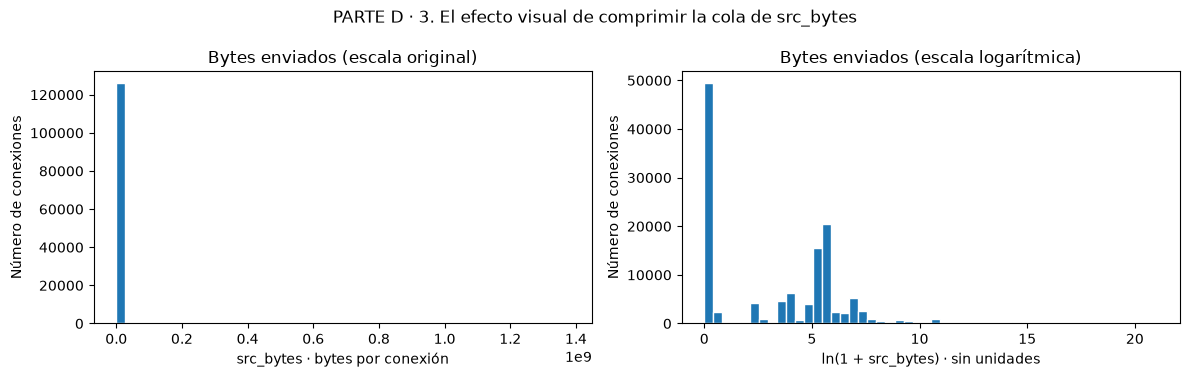

In [14]:
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

columnas_numericas = [
    "duration", "src_bytes", "dst_bytes", "count", "srv_count",
    "serror_rate", "rerror_rate", "same_srv_rate",
]

print("=" * 72)
print("PARTE D · 1. Estadísticos antes del escalado (solo entrenamiento)")
print("=" * 72)
# describe() obtiene estadísticas; seleccionamos media, desviación y extremos.
estadisticas_originales = datos_train[columnas_numericas].describe().T[
    ["mean", "std", "min", "max"]
]
display(estadisticas_originales.rename(columns={
    "mean": "Media (unidad original)",
    "std": "Desviación estándar",
    "min": "Mínimo", "max": "Máximo",
}).round(3).rename_axis("Característica"))
print("duration = segundos; src_bytes y dst_bytes = bytes; *_rate = proporciones 0–1.")

# Aprende las medias y desviaciones de cada columna SOLO con train.
escalador = StandardScaler().fit(datos_train[columnas_numericas])
matriz_escalada_train = escalador.transform(datos_train[columnas_numericas])
matriz_escalada_test = escalador.transform(datos_test[columnas_numericas])

# StandardScaler usa desviación poblacional: ddof=0.
# Si usaras pandas .std() sin argumento, su ddof=1 daría cifras muy próximas,
# pero no exactamente 1 por la convención de cálculo.
resumen_z_train = pd.DataFrame(matriz_escalada_train, columns=columnas_numericas)
resumen_z_test = pd.DataFrame(matriz_escalada_test, columns=columnas_numericas)

print("\n" + "-" * 72)
print("2. Media y desviación estándar DESPUÉS de escalar")
display(pd.DataFrame({
    "Media train (z)": resumen_z_train.mean(),
    "Desv. train (z; ddof=0)": resumen_z_train.std(ddof=0),
    "Media test (z)": resumen_z_test.mean(),
    "Desv. test (z; ddof=0)": resumen_z_test.std(ddof=0),
}).round(3).rename_axis("Característica"))

# La gráfica conserva todos los valores originales y cambia solo el eje horizontal.
figura, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
datos_train["src_bytes"].plot.hist(bins=50, ax=ejes[0], edgecolor="white")
ejes[0].set_title("Bytes enviados (escala original)")
ejes[0].set_xlabel("src_bytes · bytes por conexión")
ejes[0].set_ylabel("Número de conexiones")

np.log1p(datos_train["src_bytes"]).plot.hist(bins=50, ax=ejes[1], edgecolor="white")
ejes[1].set_title("Bytes enviados (escala logarítmica)")
ejes[1].set_xlabel("ln(1 + src_bytes) · sin unidades")
ejes[1].set_ylabel("Número de conexiones")
figura.suptitle("PARTE D · 3. El efecto visual de comprimir la cola de src_bytes")
figura.tight_layout()
plt.show()

### D.1 · Interpretación y respuestas

**«Verifica que la media de `Z_tr` es 0 y la desviación es 1».** En la tabla, las columnas **«Media train (z)»** deberían estar muy próximas a 0 y **«Desv. train (z; ddof=0)»** a 1. Es el efecto esperado de restar la media de train y dividir por su desviación. Las pequeñas diferencias visibles pueden ser redondeo o precisión numérica. **Excepción:** si una característica carece de variación, `StandardScaler` evita dividir por cero y su desviación transformada no puede ser 1; por eso antes examinamos las columnas constantes.

**«¿Por qué test no tiene necesariamente media 0 y desviación 1, y por qué es correcto?».** Porque test contiene **otras conexiones** con su propia distribución, y la transformación se calcula con medias/desviaciones de **train**, no de test. Si en train los bytes tienen media 100 y desviación 20, un registro de test con 160 bytes recibe `(160−100)/20 = +3`. **No debemos volver a centrar test con sus propias estadísticas**: en producción tampoco conoceríamos por adelantado la distribución de los próximos eventos.

**Cómo leer los histogramas:** el eje horizontal izquierdo muestra `src_bytes` en bytes reales; el derecho, `ln(1 + src_bytes)`. El eje vertical cuenta conexiones dentro de intervalos de valores (*bins*). Si casi toda la masa queda apretada a la izquierda y unas pocas conexiones extienden mucho el eje, hay una **cola derecha larga**. El logaritmo la comprime y deja ver diferencias entre valores pequeños. **El histograma no muestra una reducción de bytes transferidos**: solo cambia su representación matemática. Tampoco demuestra por sí solo que el clasificador vaya a mejorar; eso debe validarse.

**Escalado frente a logaritmo:** `StandardScaler` cambia centro y dispersión, pero no elimina una cola asimétrica; `log1p` cambia la forma de la distribución. Por eso el pipeline de la Parte F hará **primero `log1p` y después `StandardScaler`** en sus variables numéricas.

## Parte E · Convertir un `auth.log` en características útiles

**Objetivo:** un detector no entiende por sí mismo una línea de texto del registro SSH. Necesitamos extraer qué ocurrió, a qué hora, desde qué IP y con qué usuario. Después agruparemos los intentos para detectar señales que **una sola línea no muestra**: ráfagas, muchos fallos consecutivos o intentos contra varias cuentas.

**Qué significa SSH:** es un protocolo utilizado, entre otras cosas, para acceder remotamente a un equipo. El servicio `sshd` suele registrar eventos de autenticación. En este ejercicio las líneas serán **sintéticas**, es decir, **las inventamos mediante código**; no se extraen credenciales ni tráfico de terceros.

El generador construye **dos tipos de IP**:

- **40 IP consideradas legítimas**, del rango `10.10.10.0/24`, con entre 5 y 39 intentos repartidos al azar durante una semana. En cada intento la probabilidad de éxito es aproximadamente **92 %**, según `rng.random() > 0.08`.
- **12 IP que simulan fuerza bruta**, en `203.0.113.0/24`: cada una hace entre 60 y 399 intentos **fallidos** dentro de un intervalo de 30 minutos y prueba usuarios de una lista de diez cuentas. `203.0.113.0/24` es un rango reservado para documentación, no una atribución a atacantes reales.

**¿Por qué usar una semilla (`42`)?** `np.random.default_rng(42)` hace reproducible la sucesión de números aleatorios: al reiniciar y ejecutar todo, cada alumno obtiene el mismo laboratorio. **No significa que los ataques reales sean predecibles.**

El resultado inicial será una lista `eventos_ssh` de **tuplas** `(fecha, éxito, usuario, ip)`. Una tupla agrupa cuatro elementos relacionados. Luego escribiremos esas tuplas como líneas de `auth.log`, añadiremos datos de presentación (`srv`, PID, puerto) y leeremos otra vez el archivo para comprobar que podemos reconstruir una tabla.

In [15]:
import datetime as dt
import numpy as np

# Misma semilla, fechas, rangos e intervalos que el laboratorio original.
generador = np.random.default_rng(42)
inicio_semana = dt.datetime(2026, 10, 1)
usuarios_ssh = [
    "root", "admin", "carlos", "ana", "luis", "deploy",
    "test", "oracle", "ubuntu", "postgres",
]
eventos_ssh = []

# Tráfico legítimo: 40 IP; cada IP genera entre 5 y 39 intentos.
for numero_ip in range(40):
    ip = f"10.10.10.{10 + numero_ip}"
    # uniform() distribuye instantes durante siete días, expresados en segundos.
    for segundo in generador.uniform(
        0, 7 * 24 * 3600, generador.integers(5, 40)
    ):
        fecha = inicio_semana + dt.timedelta(seconds=float(segundo))
        exito = bool(generador.random() > 0.08)
        usuario = str(generador.choice(usuarios_ssh[2:6]))
        eventos_ssh.append((fecha, exito, usuario, ip))

# Simulación de fuerza bruta: 12 IP; cada una concentra intentos en 30 minutos.
for numero_ip in range(12):
    ip = f"203.0.113.{20 + numero_ip}"
    instante_base = generador.uniform(0, 7 * 24 * 3600 - 3600)
    # Los desplazamientos ordenados simulan intentos sucesivos en una ráfaga.
    for segundo in instante_base + np.sort(
        generador.uniform(0, 1800, generador.integers(60, 400))
    ):
        fecha = inicio_semana + dt.timedelta(seconds=float(segundo))
        usuario = str(generador.choice(usuarios_ssh))
        eventos_ssh.append((fecha, False, usuario, ip))

# Ordenamos cronológicamente; NO altera los valores de cada evento.
eventos_ssh.sort(key=lambda evento: evento[0])

print("=" * 72)
print("PARTE E · 1. Generar eventos de acceso SSH (datos sintéticos)")
print("=" * 72)
print(f"Eventos generados: {len(eventos_ssh):,}")
print(f"Número de IP simuladas: 40 legítimas + 12 de fuerza bruta = 52")
print(f"Primera fecha observada: {eventos_ssh[0][0]}")
print(f"Última fecha observada: {eventos_ssh[-1][0]}")
print("\nEjemplo de los primeros cinco eventos, antes de escribir auth.log:")
display(pd.DataFrame(
    eventos_ssh[:5], columns=["Fecha y hora", "¿Éxito?", "Usuario", "IP de origen"]
))

PARTE E · 1. Generar eventos de acceso SSH (datos sintéticos)
Eventos generados: 3,662
Número de IP simuladas: 40 legítimas + 12 de fuerza bruta = 52
Primera fecha observada: 2026-10-01 00:12:25.756207
Última fecha observada: 2026-10-07 23:45:59.034679

Ejemplo de los primeros cinco eventos, antes de escribir auth.log:


,Fecha y hora,¿Éxito?,Usuario,IP de origen
0,2026-10-01 00:12:25.756207,True,luis,10.10.10.22
1,2026-10-01 00:16:44.396002,True,ana,10.10.10.22
2,2026-10-01 00:23:16.345660,True,ana,10.10.10.28
3,2026-10-01 00:43:24.133124,True,deploy,10.10.10.43
4,2026-10-01 00:54:43.963681,True,luis,10.10.10.17


**Cómo interpretar la salida:** una fila representa **un intento de autenticación**, no «un atacante» ni «una sesión de 10 minutos». La columna «¿Éxito?» es booleana: `True` significa autenticación aceptada y `False` intento fallido. Que existan 12 IP de ataque **no implica que haya 12 filas de ataque**: cada IP emitirá muchos eventos y después podrá ocupar varias ventanas de 10 minutos.

### E.1 · Escribir el log y extraer sus campos con una expresión regular

Una línea sintética tendrá esta forma (los números concretos pueden variar):

```text
Oct 01 08:12:03 srv sshd[1234]: Failed password for admin from 203.0.113.20 port 2222 ssh2
```

**Interpretación:** `Oct 01 08:12:03` es la fecha sin año; `srv` el nombre del servidor; `sshd[1234]` identifica un proceso; `Failed` indica intento fallido; `admin` es el usuario probado; `203.0.113.20` la IP de origen; `2222` el puerto de origen. En líneas con `Accepted`, el acceso se acepta.

**Una expresión regular** (*regex*) es un patrón que busca partes de un texto. `re.compile(...)` prepara el patrón; `patron.match(linea)` comprueba el comienzo de una línea; `grupo(n)` recupera un fragmento entre paréntesis. En nuestro patrón:

- `^` obliga a empezar al inicio de la línea.
- `\w{3}` significa tres caracteres de palabra (`Oct`, por ejemplo); `\s+` uno o más espacios; `\d+` uno o más dígitos.
- `(Failed|Accepted)` acepta cualquiera de esas dos palabras.
- `(\S+)` captura un texto sin espacios, por ejemplo `admin` o una IP.
- Los `\[` y `\]` buscan corchetes literales de `sshd[1234]`.

**Límite consciente:** este parser reconoce el **formato exacto generado aquí**, no todos los mensajes de SSH del mundo. Un `auth.log` real puede incluir `Invalid user`, autenticación mediante clave pública, distintos formatos de fecha, años, nombres de host y campos adicionales. Esas variantes exigirían un parser más completo.

In [16]:
import re
import pandas as pd

# Escribimos el texto en disco como si fuera un registro de autenticación.
# 'w' reemplaza el archivo anterior: reiniciar y ejecutar todo no lo duplica.
with open("auth.log", "w", encoding="utf-8") as archivo_log:
    for fecha, exito, usuario, ip in eventos_ssh:
        palabra_resultado = "Accepted" if exito else "Failed"
        archivo_log.write(
            f"{fecha:%b %d %H:%M:%S} srv sshd[{generador.integers(1000, 9999)}]: "
            f"{palabra_resultado} password for {usuario} from {ip} "
            f"port {generador.integers(1024, 65000)} ssh2\n"
        )

# Paréntesis = grupos que recuperaremos: fecha, resultado, usuario, IP y puerto.
patron_auth = re.compile(
    r"^(\w{3}\s+\d+ \d\d:\d\d:\d\d) \S+ sshd\[\d+\]: (Failed|Accepted) "
    r"password for (\S+) from (\S+) port (\d+)"
)

registros_extraidos = []
lineas_sin_coincidencia = 0
with open("auth.log", "r", encoding="utf-8") as archivo_log:
    for linea in archivo_log:
        coincidencia = patron_auth.match(linea)
        if coincidencia:
            # El archivo no incluye año; usamos 2026, fijado en el generador.
            fecha = pd.to_datetime(
                "2026 " + coincidencia.group(1), format="%Y %b %d %H:%M:%S"
            )
            registros_extraidos.append({
                "ts": fecha,
                "ok": coincidencia.group(2) == "Accepted",
                "user": coincidencia.group(3),
                "ip": coincidencia.group(4),
            })
        else:
            lineas_sin_coincidencia += 1

# La nueva tabla conserva las columnas usadas en el ejercicio original.
tabla_log = pd.DataFrame(registros_extraidos)

print("=" * 72)
print("PARTE E · 2. Resultado de escribir y analizar auth.log")
print("=" * 72)
print(f"Líneas escritas en auth.log: {len(eventos_ssh):,}")
print(f"Líneas reconocidas por regex: {len(tabla_log):,}")
print(f"Líneas que no coincidieron: {lineas_sin_coincidencia}")
print("\nPrimeros cinco intentos reconstruidos del fichero:")
display(tabla_log.head().rename(columns={
    "ts": "Fecha y hora", "ok": "¿Aceptado?", "user": "Usuario", "ip": "IP de origen",
}))

# Esta comprobación es útil: no queremos perder eventos sin advertirlo.
assert len(tabla_log) == len(eventos_ssh), "El parser descartó eventos; revisa el formato."

PARTE E · 2. Resultado de escribir y analizar auth.log
Líneas escritas en auth.log: 3,662
Líneas reconocidas por regex: 3,662
Líneas que no coincidieron: 0

Primeros cinco intentos reconstruidos del fichero:


,Fecha y hora,¿Aceptado?,Usuario,IP de origen
0,2026-10-01 00:12:25,True,luis,10.10.10.22
1,2026-10-01 00:16:44,True,ana,10.10.10.22
2,2026-10-01 00:23:16,True,ana,10.10.10.28
3,2026-10-01 00:43:24,True,deploy,10.10.10.43
4,2026-10-01 00:54:43,True,luis,10.10.10.17


**Interpretación:** si «líneas reconocidas» coincide con «líneas escritas» y «líneas que no coincidieron» vale 0, el parser ha entendido **todos los eventos de este fichero sintético**. La columna `ok` conserva la misma información que «Accepted/Failed», pero en un valor lógico (`True`/`False`). La columna `ts` es una **fecha interpretable por Python**, por lo que ahora podemos ordenar, filtrar o agrupar por tiempo.

**¿Por qué no guardamos `port` en la tabla?** La expresión regular lo reconoce, pero el ejercicio original no lo usa para obtener las características posteriores. No debe confundirse «campo presente en la línea» con «campo que se utiliza para entrenar».

### E.2 · De intentos individuales a ventanas de diez minutos

**Problema:** una línea con `Failed` no es por sí sola una prueba concluyente de fuerza bruta; una persona puede equivocarse de contraseña. Es más informativo preguntar **cuántos intentos fallidos hace la misma IP en poco tiempo**.

**Ventana temporal:** dividimos el tiempo en intervalos consecutivos de 10 minutos. `dt.floor("10min")` redondea **hacia abajo** a la frontera de la ventana: `08:12` y `08:19` van a `08:10`; `08:20` pertenece a la siguiente. `groupby(["ip", "win"])` reúne todos los eventos que comparten **IP de origen y ventana temporal**. Una fila resultante representa **esa pareja**, no una conexión individual.

Para cada pareja calculamos:

| Columna | Qué significa | Ejemplo: 10 intentos, 2 aceptados, 3 usuarios |
|:--|:--|:--|
| `n` | Total de intentos de autenticación | `10` |
| `n_ok` | Intentos aceptados (`True` cuenta como 1) | `2` |
| `n_fail` | Intentos fallidos = `n − n_ok` | `8` |
| `n_users` | Usuarios distintos probados | `3` |
| `fail_ratio` | Proporción fallida = `n_fail / n` | `0,8` = **80 %** |

**Hora circular:** las 23:00 y las 00:00 están a una hora de distancia, pero como números `23` y `0` parecen estar a 23 unidades. Por eso añadimos `hora_sin = sin(2π·hora/24)` y `hora_cos = cos(2π·hora/24)`. Son dos coordenadas del mismo punto sobre un círculo. Por ejemplo, las 00:00 se representan aproximadamente `(0, 1)` y las 12:00 `(0, −1)`; las horas próximas a medianoche siguen quedando cerca en este espacio de dos dimensiones.

**Etiqueta sintética:** `label = 1` para IP del rango `203.0.113.*`, que **nosotros mismos asignamos** al generar los ataques; `0` para las demás. Es una **respuesta de laboratorio**, no un detector de IP peligrosas: fuera del experimento, pertenecer a ese prefijo no significa que alguien haya atacado.

In [17]:
# Redondeamos cada fecha al inicio de un intervalo de diez minutos.
tabla_log["win"] = tabla_log["ts"].dt.floor("10min")

# Una fila por (IP, ventana): size cuenta todos los eventos, sum cuenta éxitos,
# nunique cuenta usuarios distintos; reset_index deja IP y win como columnas.
caracteristicas_log = (
    tabla_log.groupby(["ip", "win"])
    .agg(
        n=("ok", "size"),
        n_ok=("ok", "sum"),
        n_users=("user", "nunique"),
    )
    .reset_index()
)

caracteristicas_log["n_fail"] = caracteristicas_log["n"] - caracteristicas_log["n_ok"]
caracteristicas_log["fail_ratio"] = (
    caracteristicas_log["n_fail"] / caracteristicas_log["n"]
)

# Convertimos la hora (0..23) en dos componentes para respetar su circularidad.
caracteristicas_log["hora"] = caracteristicas_log["win"].dt.hour
caracteristicas_log["hora_sin"] = np.sin(2 * np.pi * caracteristicas_log["hora"] / 24)
caracteristicas_log["hora_cos"] = np.cos(2 * np.pi * caracteristicas_log["hora"] / 24)

# Etiqueta SOLO del laboratorio: sabemos qué IP inventamos como atacantes.
caracteristicas_log["label"] = (
    caracteristicas_log["ip"].str.startswith("203.0.113.").astype(int)
)

print("=" * 72)
print("PARTE E · 3. Características por IP y ventana de 10 minutos")
print("=" * 72)
print(f"Eventos SSH originales: {len(tabla_log):,}")
print(f"Filas agregadas IP + ventana: {len(caracteristicas_log):,}")
print("\nCantidad de ventanas según su etiqueta real de laboratorio:")
display(caracteristicas_log["label"].value_counts().reindex([0, 1], fill_value=0)
        .rename(index={0: "Normal (0)", 1: "Fuerza bruta (1)"})
        .rename_axis("Clase de ventana").to_frame("Ventanas"))

print("\nEjemplo de cinco ventanas (columnas esenciales):")
display(caracteristicas_log[[
    "ip", "win", "n", "n_ok", "n_fail", "n_users", "fail_ratio", "label",
]].head(5).rename(columns={
    "ip": "IP", "win": "Inicio de ventana", "n": "Intentos",
    "n_ok": "Aceptados", "n_fail": "Fallidos", "n_users": "Usuarios distintos",
    "fail_ratio": "Proporción fallida (0–1)", "label": "Etiqueta (0/1)",
}))

PARTE E · 3. Características por IP y ventana de 10 minutos
Eventos SSH originales: 3,662
Filas agregadas IP + ventana: 838

Cantidad de ventanas según su etiqueta real de laboratorio:


,Ventanas
Clase de ventana,
Normal (0),791
Fuerza bruta (1),47



Ejemplo de cinco ventanas (columnas esenciales):


,IP,Inicio de ventana,Intentos,Aceptados,Fallidos,Usuarios distintos,Proporción fallida (0–1),Etiqueta (0/1)
0,10.10.10.10,2026-10-01 15:40:00,1,1,0,1,0.0,0
1,10.10.10.10,2026-10-01 21:30:00,1,1,0,1,0.0,0
2,10.10.10.10,2026-10-04 01:40:00,1,1,0,1,0.0,0
3,10.10.10.10,2026-10-05 21:00:00,1,1,0,1,0.0,0
4,10.10.10.10,2026-10-06 07:50:00,1,1,0,1,0.0,0


### E.3 · Preguntas resueltas y característica «ráfaga máxima»

**1. ¿Cuántas ventanas son de ataque? ¿Es una tasa base realista?** El número es el valor **«Fuerza bruta (1)»** de la tabla anterior: cada fila de la tabla agregada es una IP en un intervalo de diez minutos. La **tasa base del laboratorio** se calcula como `ventanas_de_ataque / total_de_ventanas`; la siguiente celda la muestra como porcentaje. No debemos extrapolarla a una empresa: fabricamos exactamente 12 IP atacantes, concentramos sus intentos y fijamos explícitamente sus comportamientos. La tasa resultante es una propiedad **del generador**, no una medición del mundo real.

**2. ¿Por qué no usar `ip` como característica para entrenar?** Porque nuestro generador definió las etiquetas precisamente a partir del prefijo de IP. Si el modelo ve la IP, puede aprender «203.0.113.* = ataque» sin entender **fallos, volumen o ráfagas**. Obtendría resultados engañosos y no generalizaría a una IP atacante diferente. **Sí utilizamos IP para agrupar eventos y separar conjuntos sin mezclar identidades; no la introducimos como entrada numérica del clasificador.** En un sistema real podría utilizarse información contextual de red bien validada, pero no memorizar este prefijo sintético.

**3. Añade «ráfaga máxima».** Es el **mayor número de intentos que hace una misma IP dentro de un minuto**, entre los minutos de una determinada ventana de diez minutos. Ejemplo: si durante una ventana la IP hace 1 intento a las 10:01, 4 a las 10:03 y 2 a las 10:08, la ráfaga máxima es **4 intentos/minuto**, no 7 (que sería el total de la ventana). Para calcularla, primero contamos por **IP + ventana de 10 minutos + minuto**, luego tomamos el máximo de esos conteos por **IP + ventana**.

**Observación importante:** resolver el ejercicio añade `rafaga_max` a la tabla, pero **el experimento original de la Parte F conserva sus siete características de entrada**. Así no cambiamos el algoritmo o sus resultados esperados. Más adelante puedes probar voluntariamente si incluir `rafaga_max` mejora una evaluación honesta.

In [18]:
# Solución al ejercicio original: mayor cantidad de intentos en un minuto.
# floor('1min') produce el inicio del minuto al que pertenece cada intento.
tabla_log["min"] = tabla_log["ts"].dt.floor("1min")

# Primer nivel: contamos intentos por IP, ventana de 10 min y minuto.
intentos_por_minuto = (
    tabla_log.groupby(["ip", "win", "min"])
    .size()
    .reset_index(name="intentos_en_minuto")
)

# Segundo nivel: elegimos el minuto con más intentos de cada IP/ventana.
rafagas_maximas = (
    intentos_por_minuto.groupby(["ip", "win"])["intentos_en_minuto"]
    .max()
    .reset_index(name="rafaga_max")
)

# left merge mantiene las filas existentes; solo añade la nueva columna.
# Si se repite esta celda, retiramos la versión anterior para no crear
# columnas _x/_y. La operación produce siempre el mismo resultado.
caracteristicas_log = caracteristicas_log.drop(columns=["rafaga_max"], errors="ignore").merge(
    rafagas_maximas, on=["ip", "win"], how="left", validate="one_to_one"
)

numero_ventanas_ataque = int(caracteristicas_log["label"].sum())
tasa_base_laboratorio = numero_ventanas_ataque / len(caracteristicas_log)

print("=" * 72)
print("PARTE E · 4. Ejercicio resuelto: ráfaga máxima por minuto")
print("=" * 72)
print(f"Ventanas de ataque: {numero_ventanas_ataque} de {len(caracteristicas_log)}")
print(f"Tasa base SINTÉTICA de ataque (ventanas): {tasa_base_laboratorio:.2%}")
print("\nPrimeras cinco ventanas con ráfaga máxima (intentos/minuto):")
display(caracteristicas_log[[
    "ip", "win", "n", "n_fail", "fail_ratio", "rafaga_max", "label",
]].head(5).rename(columns={
    "ip": "IP", "win": "Inicio de ventana", "n": "Intentos / 10 min",
    "n_fail": "Fallidos / 10 min", "fail_ratio": "Tasa de fallo (0–1)",
    "rafaga_max": "Máx. intentos / 1 min", "label": "Etiqueta (0/1)",
}))
print("\nComprobación: una ráfaga máxima nunca supera el total de su ventana.")
assert (caracteristicas_log["rafaga_max"] <= caracteristicas_log["n"]).all()

PARTE E · 4. Ejercicio resuelto: ráfaga máxima por minuto
Ventanas de ataque: 47 de 838
Tasa base SINTÉTICA de ataque (ventanas): 5.61%

Primeras cinco ventanas con ráfaga máxima (intentos/minuto):


,IP,Inicio de ventana,Intentos / 10 min,Fallidos / 10 min,Tasa de fallo (0–1),Máx. intentos / 1 min,Etiqueta (0/1)
0,10.10.10.10,2026-10-01 15:40:00,1,0,0.0,1,0
1,10.10.10.10,2026-10-01 21:30:00,1,0,0.0,1,0
2,10.10.10.10,2026-10-04 01:40:00,1,0,0.0,1,0
3,10.10.10.10,2026-10-05 21:00:00,1,0,0.0,1,0
4,10.10.10.10,2026-10-06 07:50:00,1,0,0.0,1,0



Comprobación: una ráfaga máxima nunca supera el total de su ventana.


**Interpretación:** «Intentos / 10 min» mide el total de una ventana, mientras que «Máx. intentos / 1 min» informa de la **concentración** dentro de ella. Dos IP podrían hacer 20 intentos en diez minutos, pero una distribuirlos a razón de dos por minuto y la otra concentrar 15 en uno solo. La segunda tiene una ráfaga máxima más alta. Esto **sugiere** una diferencia de comportamiento; no es una prueba suficiente para clasificar una IP como maliciosa.

**Advertencia sobre este dataset artificial:** todas las conexiones de las IP atacantes son fallidas, mientras que la mayoría de las legítimas se aceptan. En la vida real existen contraseñas olvidadas, escáneres autorizados, proxies, NAT y atacantes que imitan actividad humana. No hemos validado que la característica funcione en esas circunstancias.

## Parte F · Tres maneras de dividir datos y un pipeline sin fuga

**Objetivo:** responder a dos preguntas diferentes, que a menudo se confunden:

1. **¿Cómo dividimos eventos de SSH para evaluar un futuro detector?** Utilizaremos la tabla sintética `caracteristicas_log` para explorar tres estrategias de separación. **Aquí no entrenamos un modelo de SSH**: solo comparamos sus divisiones.
2. **¿Cómo entrenamos y guardamos un modelo de conexiones NSL-KDD sin contaminar test?** Construiremos un `Pipeline` con un preprocesado y una regresión logística, usando los archivos `KDDTrain+` y `KDDTest+` (que **no son** los eventos SSH).

**Por qué separar datos:** un modelo aprende de ejemplos pasados. Si durante la evaluación permitimos que una misma identidad o un evento futuro influyan sobre los parámetros que deberían conocerse solo en entrenamiento, el resultado no simula una implantación real.

**Tres divisiones de la tabla de SSH**:

| Estrategia | Cómo reparte las ventanas | Qué intenta evaluar | Principal riesgo |
|:--|:--|:--|:--|
| Aleatoria estratificada | Mezcla filas al azar; reserva 30 % y conserva aproximadamente la proporción de clases | Nuevas ventanas de una población parecida | Una misma IP puede aparecer en train y test |
| Temporal | Usa ventanas más antiguas en train y posteriores en test; corte en el cuantil 70 % | Predecir el futuro tras aprender del pasado | Las mismas IP pueden aparecer en ambas etapas; las condiciones pueden cambiar |
| Por grupos (IP) | Reserva aproximadamente 30 % de **IP distintas** para test | Generalizar a IP no vistas | No fuerza que las clases mantengan idénticas proporciones |

**«Estratificada»** significa que el muestreo intenta mantener la proporción de etiquetas; **«por grupos»** significa que todas las filas de una misma IP deben permanecer juntas. **Un 30 % de IP no implica exactamente el 30 % de ventanas**, porque unas IP tienen mucha más actividad que otras. El corte temporal se calcula mediante el **cuantil 0,7** de las fechas de ventana: es un punto que deja aproximadamente el 70 % de las observaciones a un lado, con posibles empates en las fechas.

In [19]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split

# Siete columnas numéricas, como en el experimento original de SSH.
# 'ip', 'win' y 'label' sirven para identificar, dividir y evaluar, pero NO
# entran entre las características del modelo hipotético.
columnas_entrada_ssh = [
    "n", "n_ok", "n_fail", "n_users", "fail_ratio", "hora_sin", "hora_cos",
]
X_ssh = caracteristicas_log[columnas_entrada_ssh]
y_ssh = caracteristicas_log["label"]

# 1) Aleatoria estratificada: 30 % de ventanas para test y proporción similar.
X_aleatorio_train, X_aleatorio_test, y_aleatorio_train, y_aleatorio_test = train_test_split(
    X_ssh, y_ssh, test_size=0.3, stratify=y_ssh, random_state=0
)

# 2) Temporal: corte cronológico en el cuantil 70 % de todas las ventanas.
fecha_corte = caracteristicas_log["win"].quantile(0.7)
mascara_temporal_train = caracteristicas_log["win"] <= fecha_corte
indices_temporal_train = caracteristicas_log.index[mascara_temporal_train]
indices_temporal_test = caracteristicas_log.index[~mascara_temporal_train]

# 3) Por grupos: cada IP debe aparecer íntegramente en una sola partición.
divisor_por_ip = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=0)
indices_grupo_train, indices_grupo_test = next(
    divisor_por_ip.split(X_ssh, y_ssh, groups=caracteristicas_log["ip"])
)

# Función de resumen: ayuda a comparar las tres estrategias sin repetir lógica.
def resumen_particion(nombre, indices_train, indices_test):
    ips_train = set(caracteristicas_log.loc[indices_train, "ip"])
    ips_test = set(caracteristicas_log.loc[indices_test, "ip"])
    return {
        "División": nombre,
        "Ventanas train": len(indices_train),
        "Ventanas test": len(indices_test),
        "Ataques train (%)": round(100 * y_ssh.loc[indices_train].mean(), 2),
        "Ataques test (%)": round(100 * y_ssh.loc[indices_test].mean(), 2),
        "IP presentes en ambos": len(ips_train & ips_test),
    }

comparacion_particiones = pd.DataFrame([
    resumen_particion("Aleatoria estratificada", X_aleatorio_train.index, X_aleatorio_test.index),
    resumen_particion("Temporal (cuantil 70 %)", indices_temporal_train, indices_temporal_test),
    resumen_particion("Por IP / grupos", indices_grupo_train, indices_grupo_test),
])

print("=" * 72)
print("PARTE F · 1. Comparación de tres divisiones del dataset SSH")
print("=" * 72)
display(comparacion_particiones)
print(f"\nFecha de corte temporal: {fecha_corte}")
print("Aleatoria: la misma IP puede aparecer en ambos conjuntos.")
print("Por grupos: ninguna IP debe aparecer en ambos conjuntos.")
print("Temporal: las ventanas test ocurren después de la fecha de corte.")

# Comprobaciones de las propiedades importantes de dos divisiones.
assert len(set(caracteristicas_log.loc[indices_grupo_train, "ip"]) &
           set(caracteristicas_log.loc[indices_grupo_test, "ip"])) == 0
assert (caracteristicas_log.loc[indices_temporal_train, "win"] <= fecha_corte).all()
assert (caracteristicas_log.loc[indices_temporal_test, "win"] > fecha_corte).all()

PARTE F · 1. Comparación de tres divisiones del dataset SSH


,División,Ventanas train,Ventanas test,Ataques train (%),Ataques test (%),IP presentes en ambos
0,Aleatoria estratificada,586,252,5.63,5.56,47
1,Temporal (cuantil 70 %),587,251,7.33,1.59,39
2,Por IP / grupos,617,221,5.67,5.43,0



Fecha de corte temporal: 2026-10-05 20:30:00
Aleatoria: la misma IP puede aparecer en ambos conjuntos.
Por grupos: ninguna IP debe aparecer en ambos conjuntos.
Temporal: las ventanas test ocurren después de la fecha de corte.


### F.1 · ¿Cuál es la división más honesta en producción?

**La respuesta depende de qué significa «nuevo» para tu detector.** Si el objetivo es funcionar con **IP nunca vistas**, la separación **por grupos (IP)** es más honesta que una aleatoria que permite compartir identidades: no podrá aprovechar patrones peculiares de una IP observada en train. Si tu objetivo es detectar **actividad de mañana** tras entrenar con días anteriores, es esencial una **separación temporal** para no aprender del futuro.

Para un detector de producción que debe afrontar **tanto IP nuevas como tráfico futuro**, el planteamiento más exigente suele combinar **orden temporal** y **ausencia de solapamiento de identidades**, y además dejar un periodo final totalmente reservado para evaluación. **Ninguna de las tres divisiones de este ejercicio garantiza por sí sola ambas condiciones a la vez.** Elige según la amenaza y la pregunta de evaluación; no existe una ganadora universal.

**Cómo leer la tabla:** «IP presentes en ambos» debería ser **0** en la división por grupos; en la aleatoria normalmente será mayor. «Ataques train/test (%)» muestra la tasa base de cada partición: la aleatoria estratificada intenta mantenerlas parecidas; la grupal puede variar mucho porque cada IP de fuerza bruta aporta bastantes ventanas. La columna «Ventanas test» cuenta filas, no IP diferentes.

**Otra precaución:** si construyeras características usando información del futuro —por ejemplo, sumar fallos de todo el día cuando quieres decidir en tiempo real a las 08:00— **también habría fuga**, incluso con una división temporal correcta. Aquí usamos ventanas que ya han terminado; la decisión se interpreta como una clasificación retrospectiva de la ventana terminada.

### F.2 · El pipeline: preprocesado + clasificador en un solo objeto

**Ahora volvemos a NSL-KDD**, cuyos archivos oficiales ya vienen separados en train y test. El objetivo es entrenar un detector **binario**: `is_attack=0` conexión normal; `is_attack=1` ataque. **No usamos `category`, `label`, `difficulty` ni `service_freq` como entradas.**

**¿Por qué un pipeline?** Imagina una cadena con dos máquinas: la primera prepara una conexión y la segunda decide si parece maliciosa. En `scikit-learn`, un `Pipeline` hace justamente eso: aplica los pasos en orden al entrenar y vuelve a aplicar los mismos pasos al predecir. Así es menos probable olvidar el preprocesado en producción.

Hay dos tipos de columnas y necesitan tratamientos diferentes:

- **Numéricas (`columnas_numericas_modelo`)**: `duration` (segundos), `src_bytes` y `dst_bytes` (bytes), `count` y `srv_count` (cuentas de conexiones), `serror_rate`, `rerror_rate` y `same_srv_rate` (proporciones). Se aplica **`log1p` para comprimir magnitudes no negativas** y luego `StandardScaler` para centrar y normalizar respecto a train.
- **Categóricas (`columnas_categoricas_modelo`)**: `protocol_type` (protocolo) y `flag` (estado de conexión). Se aplica **one-hot**, porque esos nombres no tienen orden numérico natural. `service` **no** entra en el pipeline de este ejercicio: el experimento anterior lo trató por separado.

`ColumnTransformer` permite aplicar un pipeline **solo a determinadas columnas** y otro procedimiento a otras columnas, y después reunir sus resultados. `LogisticRegression` es un clasificador: aprende una combinación de características y calcula una probabilidad de clase, que convierte en 0/1 mediante un umbral. **Pese al nombre «regresión», aquí se usa para clasificación, no para predecir un número continuo como una temperatura.**

**Parámetros:** `max_iter=1000` concede hasta mil iteraciones al procedimiento de ajuste para intentar converger; no significa mil datos ni mil modelos. `class_weight="balanced"` asigna mayor peso a clases menos frecuentes en **train** para que sus errores no se ignoren. Es una estrategia que puede mover el equilibrio entre falsos positivos y falsos negativos; **no garantiza mejorar todas las métricas**.

**Importante:** aunque en la Parte D escalamos variables manualmente para estudiarlas, el pipeline aprende su **propio escalador a partir de train**. No le pasamos las matrices previamente escaladas; eso evitaría aplicar el paso dos veces.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
import joblib

# Exactamente las variables del pipeline original: 8 numéricas + 2 categóricas.
columnas_numericas_modelo = [
    "duration", "src_bytes", "dst_bytes", "count", "srv_count",
    "serror_rate", "rerror_rate", "same_srv_rate",
]
columnas_categoricas_modelo = ["protocol_type", "flag"]
columnas_modelo = columnas_numericas_modelo + columnas_categoricas_modelo

# Paso numérico: primero log(1+x), después z-score.
# FunctionTransformer envuelve una función matemática en un paso de scikit-learn.
preparacion_numerica = Pipeline([
    ("log", FunctionTransformer(np.log1p)),
    ("sc", StandardScaler()),
])

# ColumnTransformer hace transformaciones diferentes según la lista de columnas.
preparador = ColumnTransformer([
    ("num", preparacion_numerica, columnas_numericas_modelo),
    ("cat", OneHotEncoder(handle_unknown="ignore"), columnas_categoricas_modelo),
])

# El último paso aprende a clasificar; lo anterior prepara los datos.
modelo_pipeline = Pipeline([
    ("prep", preparador),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

# fit SOLO sobre los registros y las respuestas de entrenamiento.
modelo_pipeline.fit(datos_train[columnas_modelo], datos_train["is_attack"])

# predict prepara test con los parámetros aprendidos en train y devuelve 0 o 1.
entradas_test_nsl = datos_test[columnas_modelo]
predicciones_test_nsl = modelo_pipeline.predict(entradas_test_nsl)

print("=" * 72)
print("PARTE F · 2. Clasificador NSL-KDD con Pipeline sin fuga")
print("=" * 72)
print(f"Entrenamiento: {len(datos_train):,} conexiones etiquetadas")
print(f"Evaluación: {len(datos_test):,} conexiones reservadas")
print(f"Entradas: {len(columnas_numericas_modelo)} numéricas + "
      f"{len(columnas_categoricas_modelo)} categóricas")
print("Clase 0 = normal; clase 1 = ataque")
print("\nINFORME DE CLASIFICACIÓN · Solo con el conjunto de prueba")
print(classification_report(
    datos_test["is_attack"], predicciones_test_nsl,
    labels=[0, 1], target_names=["Normal (0)", "Ataque (1)"], zero_division=0,
))

# Matriz de confusión: filas = clase real, columnas = predicción.
matriz_confusion_nsl = confusion_matrix(
    datos_test["is_attack"], predicciones_test_nsl, labels=[0, 1]
)
print("Matriz de confusión (filas = realidad; columnas = predicción):")
display(pd.DataFrame(
    matriz_confusion_nsl,
    index=["Real: normal (0)", "Real: ataque (1)"],
    columns=["Predicho: normal (0)", "Predicho: ataque (1)"],
))

# Respondemos a la pregunta del ejercicio con los valores REALES de esta ejecución.
# Recordatorio: recall = detectados de la clase / total real de esa clase.
recall_normal = float(matriz_confusion_nsl[0, 0] / matriz_confusion_nsl[0].sum())
recall_ataque = float(matriz_confusion_nsl[1, 1] / matriz_confusion_nsl[1].sum())
if abs(recall_normal - recall_ataque) < 1e-12:
    print("\nRespuesta: ambas clases tienen el mismo recall en esta ejecución.")
else:
    peor_clase = "Normal (0)" if recall_normal < recall_ataque else "Ataque (1)"
    print(f"\nRespuesta: la clase peor detectada por RECALL es {peor_clase}.")
print(f"Recall normal = {recall_normal:.2%} | recall ataque = {recall_ataque:.2%}")

# Guardamos TANTO el preprocesado como el clasificador en un único archivo.
archivo_modelo = "pipe_ia2.joblib"
joblib.dump(modelo_pipeline, archivo_modelo)
print(f"\nModelo entrenado y preprocesado guardados en: {archivo_modelo}")
print("Este archivo puede cargarse en otra aplicación Python con joblib.load().")

PARTE F · 2. Clasificador NSL-KDD con Pipeline sin fuga
Entrenamiento: 125,973 conexiones etiquetadas
Evaluación: 22,544 conexiones reservadas
Entradas: 8 numéricas + 2 categóricas
Clase 0 = normal; clase 1 = ataque

INFORME DE CLASIFICACIÓN · Solo con el conjunto de prueba
              precision    recall  f1-score   support

  Normal (0)       0.67      0.97      0.80      9711
  Ataque (1)       0.97      0.64      0.77     12833

    accuracy                           0.78     22544
   macro avg       0.82      0.81      0.78     22544
weighted avg       0.84      0.78      0.78     22544

Matriz de confusión (filas = realidad; columnas = predicción):


,Predicho: normal (0),Predicho: ataque (1)
Real: normal (0),9443,268
Real: ataque (1),4588,8245



Respuesta: la clase peor detectada por RECALL es Ataque (1).
Recall normal = 97.24% | recall ataque = 64.25%

Modelo entrenado y preprocesado guardados en: pipe_ia2.joblib
Este archivo puede cargarse en otra aplicación Python con joblib.load().


### F.3 · Interpretar el informe, la matriz y la respuesta «qué clase peor detectada»

`classification_report` muestra métricas **por clase**. Para cada clase, cambia la pregunta de qué es un resultado positivo:

- **Precision (precisión):** entre las conexiones que el modelo **predijo** como esa clase, ¿qué fracción acertó? Si el modelo marcó 10 ataques y 7 eran realmente ataques, la precisión de «Ataque (1)» es `7/10 = 70 %`. Una precisión baja implica muchas alertas erróneas entre las positivas.
- **Recall (sensibilidad / cobertura):** entre las conexiones que **realmente eran** esa clase, ¿qué fracción encontró? Si había 20 ataques reales y detectó 7, su *recall* de ataque es `7/20 = 35 %`. Un recall bajo en «Ataque (1)» significa muchos ataques pasados por alto.
- **F1-score:** combina precisión y recall mediante su media armónica: `F1 = 2·precision·recall / (precision+recall)`. Es alta solo si ambas son razonables.
- **Support:** cuántos ejemplos **reales** hay de esa clase en test. No es una métrica de calidad.
- **Accuracy:** aciertos totales / filas totales. Puede esconder una cobertura muy baja de ataques raros.
- **Macro avg:** promedio simple de las clases; les da la misma importancia sin importar su tamaño. **Weighted avg:** promedio ponderado por *support*; pesa más las clases frecuentes.

**Cómo leer la matriz de confusión (filas = realidad; columnas = predicción):**

| | Predice normal (0) | Predice ataque (1) |
|:--|:--|:--|
| **Realmente normal (0)** | Verdadero negativo (**TN**): no genera una alerta innecesaria | Falso positivo (**FP**): alerta errónea |
| **Realmente ataque (1)** | Falso negativo (**FN**): ataque no detectado | Verdadero positivo (**TP**): ataque detectado |

**Ejemplo numérico:** si la matriz fuese `[[80, 20], [5, 95]]`, habría 80 normales bien clasificados, 20 falsas alertas, 5 ataques escapados y 95 ataques detectados. La precisión de ataque sería `95/(95+20) ≈ 82,6 %` y su recall `95/(95+5) = 95 %`. **Ese ejemplo no son los resultados del notebook**: mira los valores que realmente produzca la celda.

**Pregunta: «¿Qué clase se detecta peor?»** Compara sobre todo la columna **`recall`** de `Normal (0)` y `Ataque (1)` del informe anterior. **La clase cuyo recall sea menor es la que el modelo deja escapar con mayor frecuencia respecto a los casos reales de esa clase.** También compara F1 si te interesa un compromiso entre cobertura y precisión. No sería riguroso afirmar de antemano cuál es peor sin ver la salida de la ejecución.

**Pregunta: «¿Cuál de las tres divisiones es más honesta?»** Se refiere al experimento de **SSH**, no al archivo NSL-KDD ya separado. La respuesta razonada está en F.1: temporal para futuro; por grupos para IP nuevas; combinar ambas cuando el despliegue lo exige.

**Regla clave:** `log1p` solo se usa con datos **no negativos** como los valores elegidos de NSL-KDD. Si una aplicación posterior incluye valores negativos, habría que elegir o justificar otra transformación.

### F.4 · ¿Dónde está el modelo y cómo lo usaríamos fuera del notebook?

Un modelo entrenado no es únicamente el texto del código: son **parámetros aprendidos**. Al guardar `modelo_pipeline` en `pipe_ia2.joblib`, guardamos en un archivo tanto el mapa de categorías y las estadísticas del escalador como los coeficientes de la regresión logística.

La celda siguiente **no vuelve a entrenar**. Carga el archivo, toma una conexión del test y muestra qué devuelve. La entrada debe tener las **mismas columnas originales** utilizadas al entrenar, con nombres y formatos compatibles. El pipeline realiza por dentro `log1p`, escalado y one-hot antes de producir su predicción. Para conectarlo a una API o a un sistema de eventos, otra aplicación tendría que transformar sus eventos reales en esas mismas diez características, validar su formato y llamar a `predict` o `predict_proba`.

**Seguridad:** `joblib.load()` utiliza un formato de serialización basado en pickle. **No cargues archivos `.joblib` de procedencia desconocida**: deserializarlos puede ejecutar código. El ejemplo usa el archivo que el propio notebook acaba de guardar.

In [21]:
# Ejemplo concreto de reutilización: cargar el pipeline y clasificar UNA fila.
modelo_recuperado = joblib.load("pipe_ia2.joblib")
conexion_ejemplo = datos_test[columnas_modelo].iloc[[0]]  # doble []: conserva el DataFrame
etiqueta_real_ejemplo = int(datos_test["is_attack"].iloc[0])
prediccion_ejemplo = int(modelo_recuperado.predict(conexion_ejemplo)[0])
probabilidad_ataque_ejemplo = float(modelo_recuperado.predict_proba(conexion_ejemplo)[0, 1])

print("=" * 72)
print("PARTE F · 3. Reutilizar el pipeline guardado")
print("=" * 72)
print("Entrada: primera conexión del archivo de PRUEBA (valores originales).")
display(conexion_ejemplo.reset_index(drop=True))
print(f"\nRespuesta real disponible para evaluar: {etiqueta_real_ejemplo} "
      f"({'ataque' if etiqueta_real_ejemplo else 'normal'})")
print(f"Predicción del modelo: {prediccion_ejemplo} "
      f"({'ataque' if prediccion_ejemplo else 'normal'})")
print(f"Probabilidad estimada de ataque según el modelo: {probabilidad_ataque_ejemplo:.2%}")
print("Es una estimación del modelo, no una probabilidad calibrada de la red real.")

PARTE F · 3. Reutilizar el pipeline guardado
Entrada: primera conexión del archivo de PRUEBA (valores originales).


,duration,src_bytes,dst_bytes,count,srv_count,serror_rate,rerror_rate,same_srv_rate,protocol_type,flag
0,0,0,0,229,10,0.0,1.0,0.04,tcp,REJ



Respuesta real disponible para evaluar: 1 (ataque)
Predicción del modelo: 1 (ataque)
Probabilidad estimada de ataque según el modelo: 95.41%
Es una estimación del modelo, no una probabilidad calibrada de la red real.


**Cómo interpretar el ejemplo:** «respuesta real» está disponible **porque este es un archivo de evaluación etiquetado**; en producción, al recibir un evento nuevo, esa respuesta normalmente **no** se conoce. «Predicción» es la clase que decide el pipeline. `predict_proba` devuelve puntuaciones estimadas para las clases, no una garantía de certeza ni una calibración validada en un SOC real. En un despliegue sería necesario comprobar estabilidad, tasa base, falsos positivos y mantenimiento del modelo.

## Parte G · Ampliación: detectar U2R cuando hay muy pocos ejemplos

**Objetivo:** diferenciar «tener mucha exactitud» de «detectar una clase extremadamente rara». U2R (*User-to-Root*) agrupa ataques en los que un usuario intenta elevar privilegios. En NSL-KDD hay **muy pocos U2R** frente al resto, por lo que un clasificador podría acertar en casi todas las conexiones aun ignorando precisamente esos ataques.

Creamos una **nueva etiqueta binaria** `es_u2r`: 1 si `category == "u2r"`, y 0 en cualquier otro caso, incluidos otros ataques. **Es un problema distinto** del detector anterior `is_attack` (ataque de cualquier tipo frente a normal).

Compararemos **tres versiones de Random Forest**, un método que combina muchos árboles de decisión para clasificar:

1. **Sin tratar:** entrena 200 árboles con la distribución original.
2. **`class_weight="balanced"`:** durante el entrenamiento, los errores de la clase poco frecuente reciben mayor peso. **No crea filas nuevas**.
3. **SMOTE aplicado solo a train:** crea muestras **sintéticas** de la clase minoritaria interpolando entre vecinos. Si dos ejemplos minoritarios tienen una característica numérica `2` y `6`, un ejemplo artificial podría tomar un valor intermedio, como `4`. No es una copia exacta del original ni implica que la conexión sintética exista realmente.

**Parámetros de SMOTE:** `k_neighbors=3` busca tres vecinos cercanos de la misma clase minoritaria para generar nuevas muestras; por eso hacen falta suficientes ejemplos minoritarios en train. `random_state=0` fija la aleatoriedad. **Precaución:** algunas características U2R son contadores o indicadores binarios. Interpolar números puede generar valores fraccionarios sin interpretación literal (p. ej., «0,4 intentos de root shell»); este experimento sirve para comparar métodos, **no** demuestra que las muestras generadas sean conexiones plausibles.

**¿Qué métricas importan?** `recall_U2R = TP/(TP+FN)` muestra qué fracción de U2R reales detectamos. `precision_U2R = TP/(TP+FP)` muestra qué fracción de alertas U2R son correctas. Queremos aumentar la cobertura sin producir tantas falsas alertas que el detector resulte inutilizable. Con una clase muy rara, un pequeño número de falsas alertas puede hundir la precisión.

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score
from imblearn.over_sampling import SMOTE

# Una etiqueta diferente: 1 SOLO para U2R; 0 para normal y los demás ataques.
for tabla in (datos_train, datos_test):
    tabla["es_u2r"] = (tabla["category"] == "u2r").astype(int)

# Mismas 13 características numéricas que la ampliación original.
columnas_u2r = columnas_numericas_modelo + [
    "logged_in", "num_root", "num_file_creations", "num_shells", "root_shell",
]

print("=" * 72)
print("PARTE G · 1. Desbalanceo de la clase U2R")
print("=" * 72)
display(pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Conexiones totales": [len(datos_train), len(datos_test)],
    "U2R reales": [int(datos_train["es_u2r"].sum()), int(datos_test["es_u2r"].sum())],
    "Proporción U2R (%)": [
        100 * datos_train["es_u2r"].mean(),
        100 * datos_test["es_u2r"].mean(),
    ],
}).round(3))

# Guarda métricas y cantidades para comparar los tres enfoques después.
resultados_u2r = []

def evaluar_u2r(modelo, X_entrenamiento, y_entrenamiento, nombre):
    """Entrena un modelo U2R y lo evalúa SIEMPRE con el mismo test intacto."""
    modelo.fit(X_entrenamiento, y_entrenamiento)
    predicciones_u2r = modelo.predict(datos_test[columnas_u2r])
    resultado = {
        "Estrategia": nombre,
        "Ejemplos train": len(X_entrenamiento),
        "Recall U2R (%)": 100 * recall_score(datos_test["es_u2r"], predicciones_u2r, zero_division=0),
        "Precisión U2R (%)": 100 * precision_score(datos_test["es_u2r"], predicciones_u2r, zero_division=0),
        "U2R detectados (TP)": int(((datos_test["es_u2r"] == 1) & (predicciones_u2r == 1)).sum()),
        "Falsas alertas U2R (FP)": int(((datos_test["es_u2r"] == 0) & (predicciones_u2r == 1)).sum()),
    }
    resultados_u2r.append(resultado)
    print(f"Finalizado: {nombre}")

# Mismo Random Forest, misma semilla y mismos 200 árboles en los tres casos.
def crear_random_forest(**parametros):
    return RandomForestClassifier(
        n_estimators=200, random_state=0, n_jobs=-1, **parametros
    )

# 1) Referencia: clases en proporciones originales.
evaluar_u2r(
    crear_random_forest(), datos_train[columnas_u2r], datos_train["es_u2r"], "Sin tratar"
)

# 2) Costes de errores ponderados; sin generar filas.
evaluar_u2r(
    crear_random_forest(class_weight="balanced"),
    datos_train[columnas_u2r], datos_train["es_u2r"], "Class weight",
)

# 3) SIMPLEMENTE ENTRENAMIENTO: no ve test ni genera filas a partir de él.
X_sintetico_train, y_sintetico_train = SMOTE(
    random_state=0, k_neighbors=3
).fit_resample(datos_train[columnas_u2r], datos_train["es_u2r"])

evaluar_u2r(
    crear_random_forest(), X_sintetico_train, y_sintetico_train, "SMOTE solo train"
)

print("\n" + "-" * 72)
print("2. Comparación sobre el MISMO conjunto de prueba NSL-KDD")
display(pd.DataFrame(resultados_u2r).round(2))
print("Recuerda: recall = proporción de U2R reales detectados.")
print("Precisión = proporción de alertas U2R que sí eran U2R.")

# Respuesta numérica al ejercicio: diferencia contra el modelo SIN tratar.
referencia_u2r = resultados_u2r[0]
for experimento in resultados_u2r[1:]:
    cambio_recall = experimento["Recall U2R (%)"] - referencia_u2r["Recall U2R (%)"]
    cambio_precision = experimento["Precisión U2R (%)"] - referencia_u2r["Precisión U2R (%)"]
    print(f"\n{experimento['Estrategia']} frente a sin tratar:")
    print(f"  Cambio de recall: {cambio_recall:+.2f} puntos porcentuales.")
    print(f"  Cambio de precisión: {cambio_precision:+.2f} puntos porcentuales.")
    print(f"  Falsas alertas U2R: {referencia_u2r['Falsas alertas U2R (FP)']} "
          f"→ {experimento['Falsas alertas U2R (FP)']}.")
    print("  Un cambio positivo de recall indica más cobertura; uno negativo, menos.")

PARTE G · 1. Desbalanceo de la clase U2R


,Conjunto,Conexiones totales,U2R reales,Proporción U2R (%)
0,Entrenamiento,125973,52,0.041
1,Prueba,22544,67,0.297


Finalizado: Sin tratar
Finalizado: Class weight
Finalizado: SMOTE solo train

------------------------------------------------------------------------
2. Comparación sobre el MISMO conjunto de prueba NSL-KDD


,Estrategia,Ejemplos train,Recall U2R (%),Precisión U2R (%),U2R detectados (TP),Falsas alertas U2R (FP)
0,Sin tratar,125973,29.85,95.24,20,1
1,Class weight,125973,32.84,81.48,22,5
2,SMOTE solo train,251842,35.82,12.24,24,172


Recuerda: recall = proporción de U2R reales detectados.
Precisión = proporción de alertas U2R que sí eran U2R.

Class weight frente a sin tratar:
  Cambio de recall: +2.99 puntos porcentuales.
  Cambio de precisión: -13.76 puntos porcentuales.
  Falsas alertas U2R: 1 → 5.
  Un cambio positivo de recall indica más cobertura; uno negativo, menos.

SMOTE solo train frente a sin tratar:
  Cambio de recall: +5.97 puntos porcentuales.
  Cambio de precisión: -82.99 puntos porcentuales.
  Falsas alertas U2R: 1 → 172.
  Un cambio positivo de recall indica más cobertura; uno negativo, menos.


### G.1 · Interpretación y preguntas resueltas

**«¿Mejora el recall? ¿A qué coste en precisión?»** Compara las filas «Sin tratar», «Class weight» y «SMOTE solo train» de la tabla anterior. **Hay mejora del recall si el porcentaje es mayor**, no por el simple hecho de aplicar SMOTE. Si pasa del 20 % al 60 %, significa que antes encontraba 2 de cada 10 U2R y ahora 6 de cada 10. **El posible coste** es bajar precisión al generar más falsas alarmas U2R: revisa las columnas «Precisión U2R (%)» y «Falsas alertas U2R (FP)». Puede haber mejoras, empeoramientos o empates; no afirmamos el resultado antes de ejecutarlo.

**«¿Por qué aplicar SMOTE antes de dividir infla el resultado?»** Porque muestras muy parecidas, incluso sintéticas derivadas de otras, podrían terminar repartidas entre entrenamiento y prueba. Entonces un ejemplo de test se parecería artificialmente a un ejemplo construido para train, y el modelo habría visto información estrechamente relacionada con su futura evaluación. Además, crear sintéticos con todo el dataset usaría también la distribución de la clase de test. **Procedimiento correcto:** separar primero y llamar a `SMOTE.fit_resample(...)` **solo sobre train**. Si existe validación cruzada, SMOTE debe ejecutarse **dentro de cada partición de entrenamiento**, nunca sobre los datos de validación.

**«¿Por qué no basta con accuracy?»** Imagina 10.000 conexiones, de las cuales solo 10 son U2R. Un modelo que **siempre diga «no U2R»** acierta 9.990/10.000 = **99,9 % de exactitud**, pero su recall de U2R es **0 %**. Por eso medimos explícitamente U2R y contamos tanto los detectados como las falsas alarmas.

**Límites de esta demostración:** el modelo ve un benchmark histórico con muchos más casos de los que vería una red contemporánea. La baja prevalencia y las variables interpoladas exigen precaución. Un análisis de producción debería estudiar curvas precisión-recall, umbrales de alerta, coste de investigar falsos positivos y separación temporal o por entorno.

## Tabla de decisiones de preprocesado · 15 características justificadas

El ejercicio original pide un mínimo de **12 columnas**. Esta tabla contiene **15 ejemplos** de NSL-KDD. **No afirma que todas las columnas aparezcan juntas en el pipeline final**: indica opciones utilizadas en el laboratorio o decisiones justificadas que podrías aplicar a un modelo distinto. Una decisión de preparación debe depender de lo que significa cada variable y de qué modelo va a consumirla.

| Característica | Tipo y significado | Tratamiento propuesto | Razón y precaución |
|:--|:--|:--|:--|
| `src_bytes` | Numérica: bytes enviados desde el origen | `log1p` + z-score | Puede tener valores extremos; ambas transformaciones usan parámetros calculados con train |
| `dst_bytes` | Numérica: bytes hacia el origen | `log1p` + z-score | Evita que conexiones enormes dominen la escala; verificar no negatividad |
| `duration` | Numérica: segundos de conexión | `log1p` + z-score | Duraciones pueden ser asimétricas; cero segundos se conserva como cero tras `log1p` |
| `count` | Numérica: recuento de conexiones recientes | `log1p` + z-score | Reduce diferencias extremas y permite usarla con regresión logística |
| `srv_count` | Numérica: conexiones recientes al mismo servicio | `log1p` + z-score | Recuento no negativo; puede diferir en escala respecto a proporciones |
| `serror_rate` | Numérica: tasa de errores SYN | `log1p` + z-score en el pipeline original | En 0–1 el log tiene poco efecto; se mantiene para reproducir el pipeline |
| `rerror_rate` | Numérica: tasa de errores REJ | `log1p` + z-score en el pipeline original | Es una proporción; podría bastar escalado en otro diseño |
| `same_srv_rate` | Numérica: proporción de servicios iguales | `log1p` + z-score en el pipeline original | No hay categorías; evita fuga al ajustar solo con train |
| `protocol_type` | Categórica: TCP, UDP, ICMP | One-hot | Los nombres no tienen orden; tres categorías habituales en NSL-KDD |
| `flag` | Categórica: estado de la conexión | One-hot | Distingue estados sin fingir que uno es «mayor» |
| `service` | Categórica: nombre de servicio | One-hot o frecuencia | One-hot crea muchas columnas; frecuencia es compacta y se calcula en train |
| `logged_in` | Binaria: inicio de sesión conseguido | Conservar como 0/1 | Ya codifica una condición; presente en las características del ejercicio U2R |
| `root_shell` | Binaria: presencia de shell root | Conservar como 0/1 | No requiere one-hot; puede ser importante para U2R, pero hay que comprobar cuándo se conoce |
| `num_failed_logins` | Numérica: intentos fallidos registrados | Conservar o escalar según el modelo | Cuenta eventos; no debe confundirse con una etiqueta de ataque |
| `num_outbound_cmds` | Numérica que puede ser constante en train | Eliminar **si** no varía en train | Sin variación no ayuda a distinguir las filas; comprobarlo en la Parte A |

**Ejemplo para interpretar la tabla:** `protocol_type` no se escala como si `tcp` y `udp` fueran distancias; se convierte en indicadores. `src_bytes`, en cambio, es una cantidad real para la que puede tener sentido comprimir extremos y luego escalar. Estas elecciones no «mejoran la IA» por definición: hacen que los datos sean adecuados para **ese algoritmo** y deben compararse con una evaluación fiable.

## Cierre de la sesión · Conectar todas las piezas

**El recorrido de NSL-KDD ha sido:** archivos de conexiones → inspección y limpieza de columnas constantes → agrupación de etiquetas para análisis → codificaciones numéricas → escalado de variables → pipeline de clasificación → informe, matriz de confusión y archivo de modelo → experimento U2R con desbalanceo.

**El recorrido del log SSH ha sido:** eventos sintéticos con fecha, IP y resultado → archivo de texto → parser con regex → agregación por IP y ventana de diez minutos → características (fallos, usuarios, ráfaga, hora circular) → tres estrategias para dividir el conjunto. **Los dos recorridos no se mezclan en un único entrenamiento**: responden a tareas distintas del mismo laboratorio.

**Cinco preguntas de autoevaluación, con respuesta breve:**

1. **¿Por qué se llama `fit` con train y solo `transform` con test?** Porque los parámetros de preparación se deben aprender sin consultar datos reservados para evaluación.
2. **¿Qué significa `fail_ratio = 0,8`?** Que el 80 % de los intentos de esa IP durante esa ventana fallaron; por sí solo no prueba que sea un ataque.
3. **¿Por qué no basta con la accuracy en U2R?** Porque una clase muy rara puede quedar casi totalmente sin detectar y, aun así, obtenerse una exactitud global altísima.
4. **¿Qué diferencia hay entre «dividir por IP» y «usar IP como entrada»?** Dividir por IP evita que una identidad esté en ambos conjuntos; usar su valor como entrada podría llevar a memorizarla. Son objetivos opuestos.
5. **¿Qué guarda el archivo `.joblib`?** El pipeline ya ajustado: transformaciones aprendidas en train y parámetros del clasificador; permite aplicarlos a conexiones nuevas con el mismo formato.

### Antes de entregar

- **Ejecuta todo desde un kernel recién iniciado.** Comprueba que `utils.py` no crece por duplicados y que las tablas muestran etiquetas y unidades claras.
- **Revisa las respuestas con tus resultados reales.** En particular: duplicados, solapamientos, clase peor detectada y efecto de SMOTE. Las explicaciones indican qué números mirar sin inventar cifras.
- **Guarda los archivos si vas a continuar fuera del notebook:** `utils.py` (funciones), `auth.log` (log sintético) y `pipe_ia2.joblib` (modelo entrenado). En Colab puedes descargarlos desde el panel de archivos. `data/` contiene NSL-KDD.
- **Recuerda la condición de uso responsable:** el dataset no representa tráfico moderno y las etiquetas sintéticas del log no son inteligencia de amenazas sobre direcciones IP reales.

**Resultado de aprendizaje:** ya puedes explicar **qué sabe cada transformación, de dónde lo aprende, en qué orden se aplica, cómo leer la evaluación y cuándo un resultado es engañoso por fuga de información**.